# Objectif 

Analyse de la structure de variété pour la portion 1. 

Date de création : 20/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 1
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB ...
│   │           tir_src_lat            (src_datetime) float64 3kB ...
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB ...
│   │           tir_src_lat            (src_datetime) float64 2kB ...
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

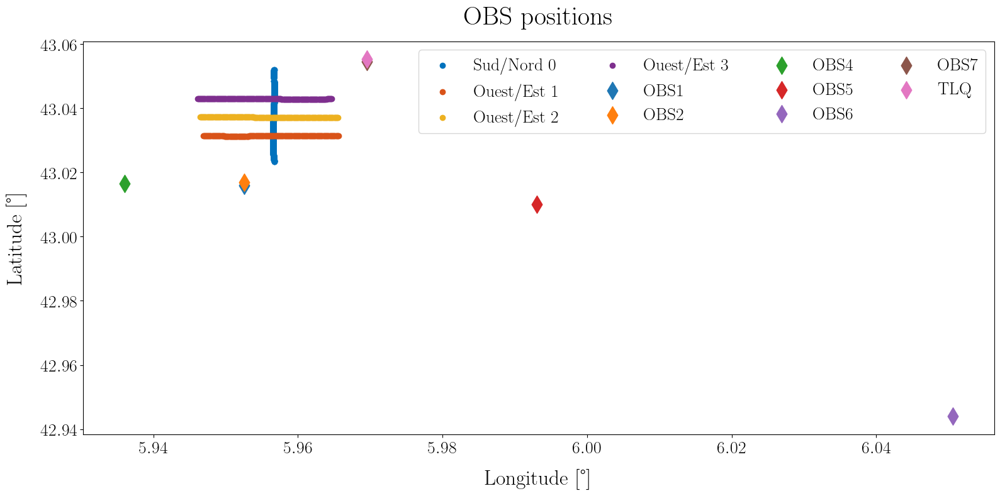

In [4]:
plot_portion_tir_pos(portion_tree=portion)

# Correction de la position des OBS

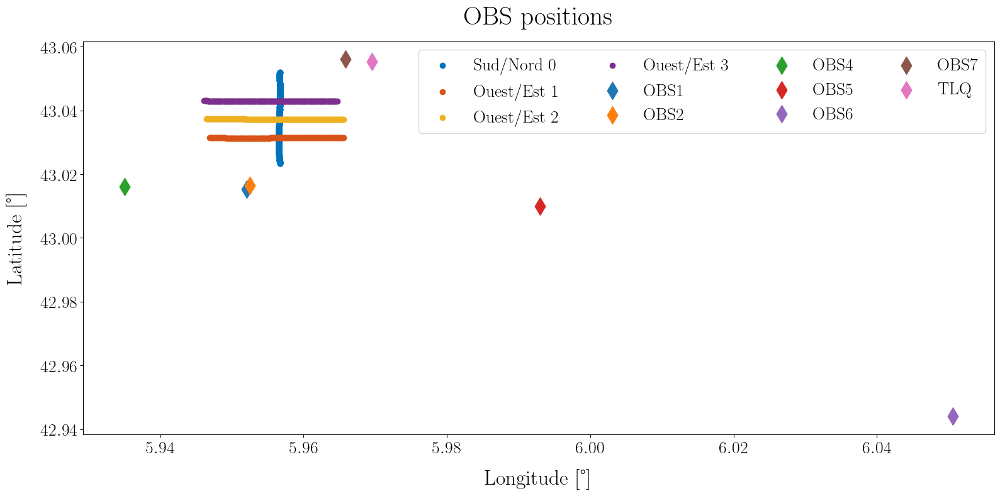

In [5]:
apply_obs_pos_correction = True 

if apply_obs_pos_correction:
    apply_rcv_position_correction_to_portion(portion_tree=portion)
    portion
    plot_portion_tir_pos(portion_tree=portion)

# Calcul des grandeurs signantes 

In [6]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB 5.957 5.957 ... 5.957
│   │           tir_src_lat            (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB 4.11e+03 ... 3...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB 5.947 5.947 ... 5.966
│   │           tir_src_lat            (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB 1.849e+03 ... ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1

## Extraction de chaques émissions

### Calcul de la célérité équivalente 

In [7]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

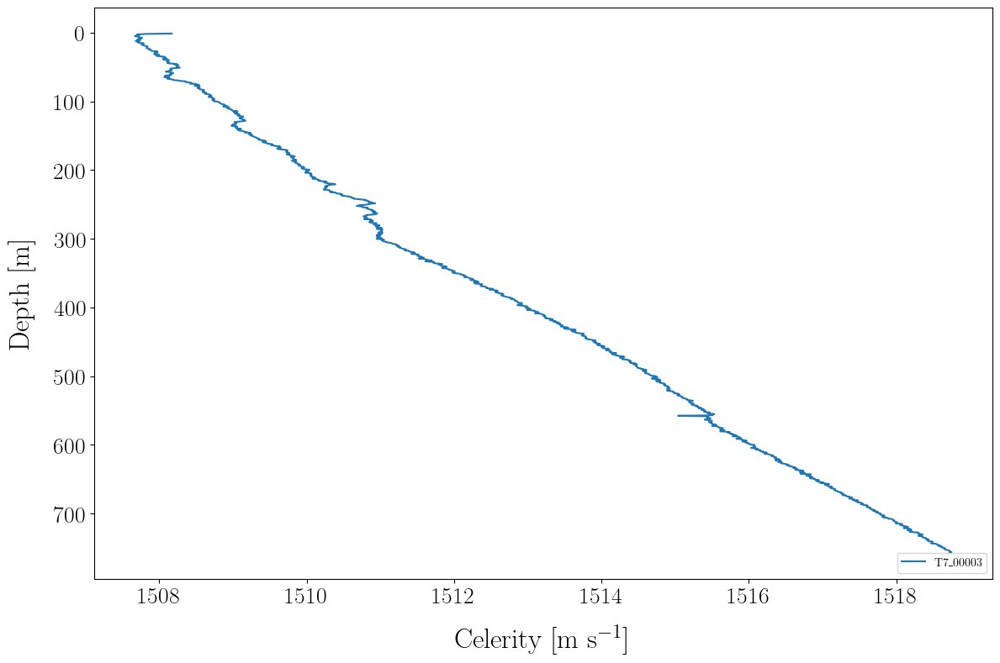

In [8]:
selected_profile = "T7_00003"
# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds = node.to_dataset()
        ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

    # ds = node.to_dataset()
    # ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)


# for ax in axs.flatten():
ax.legend(loc="lower right", ncols=2, fontsize=10)
# axs[1].legend(loc="upper right", ncols=2, fontsize=10)
# axs[1].set_ylabel("")

# plt.ylim(500, 0)

In [9]:
ds_ = ds.sel(depth=slice(0, 100))
c_eq = equivalent_celerity(ds_.celerity.values, ds_.celerity.depth.values)
c_eq

np.float64(1508.1731018573482)

### Calcul des temps de propagation associés à chaque couple émission / récepteur 

In [10]:
c0 = c_eq
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

### Comparaison aux signaux 

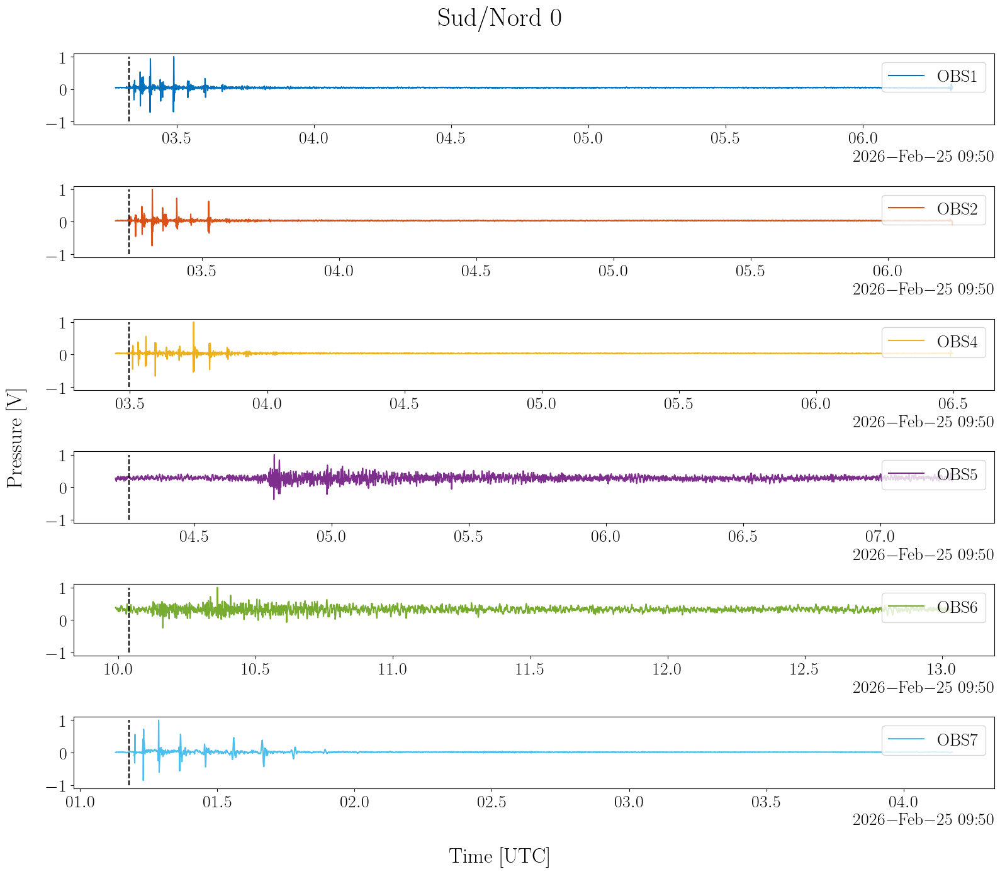

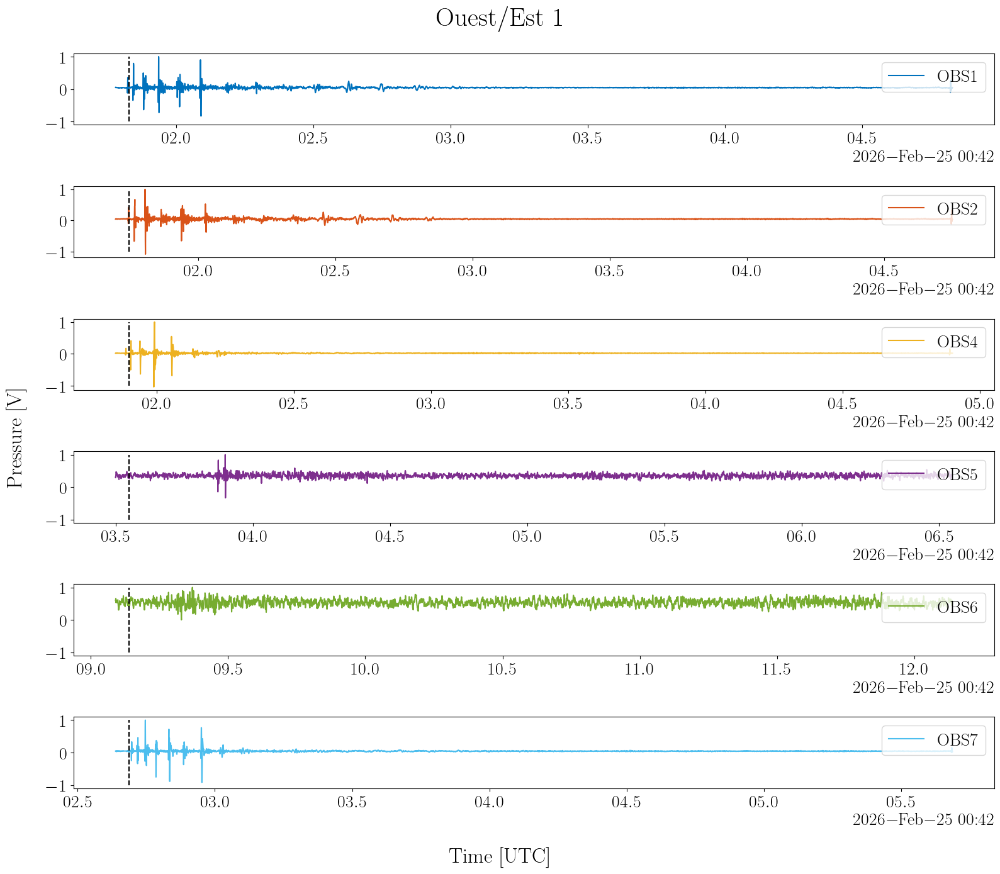

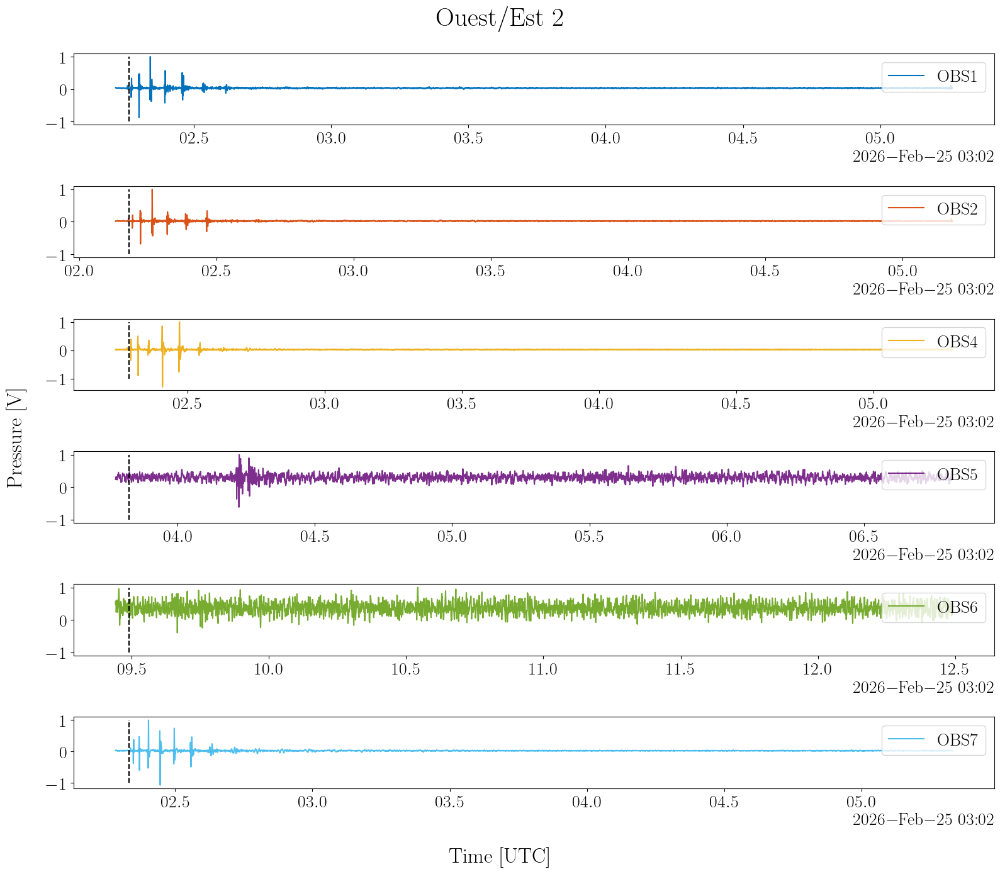

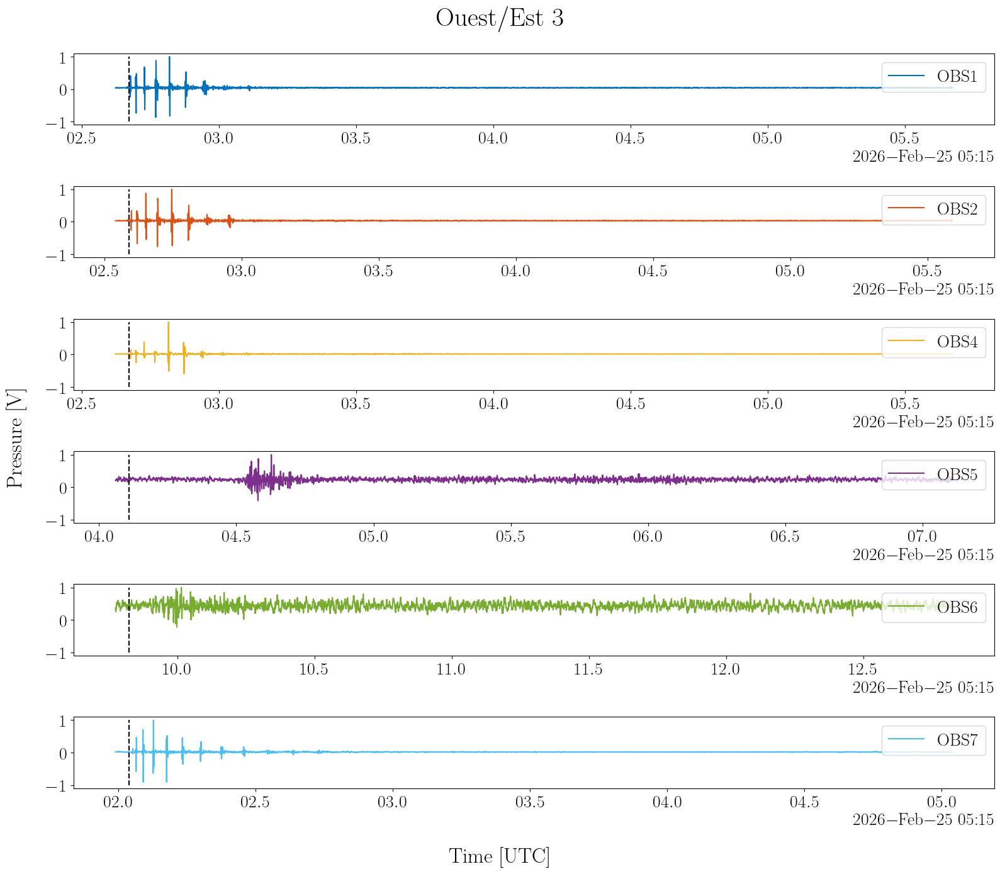

In [11]:
nb_tir = 1
offset1 = 50
offset2 = 3000

obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

# Calcul des grandeurs signantes 

In [12]:
derive_portion_cpsd(
    portion_tree=portion, offset_ms=100, signal_duration_s=3, nfft=2**15, obs_ids=None
)
portion

C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\acouplane\src\acouplane_utils.py:980: RuntimeWarning: Mean of empty slice
  signal_i = signal_i - np.nanmean(signal_i)


<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB ...
│   │           atl_lat                 (atl_datetime) float64 9kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon          (src_datetime) float64 3kB ...
│   │           tir_vessel_lat          (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 22kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 22kB 2.726 ... 2.458
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 22kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon          (src_datetime) float64 2kB ...
│   │           tir_vessel_lat          (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 11kB 1.849e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 11kB 1.229 ... 1.773
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 11kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\3625969037.py:28: RuntimeWarning: divide by zero encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\3625969037.py:28: RuntimeWarning: invalid value encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\3625969037.py:28: RuntimeWarning: divide by zero encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\3625969037.py:28: RuntimeWarning: invalid value encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\3625969037.py:28: RuntimeWarning: divide by zero encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
C:\Users\baptiste.menetrier\AppData\Local\Temp\

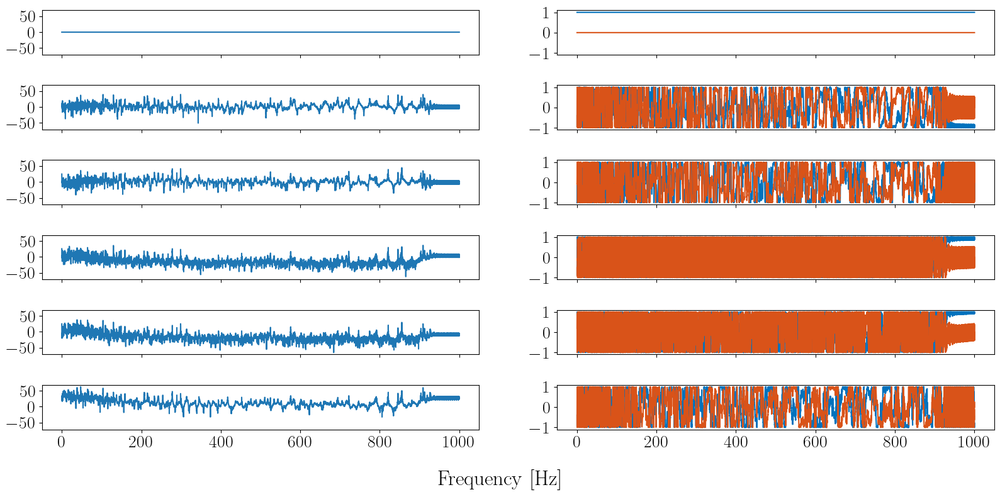

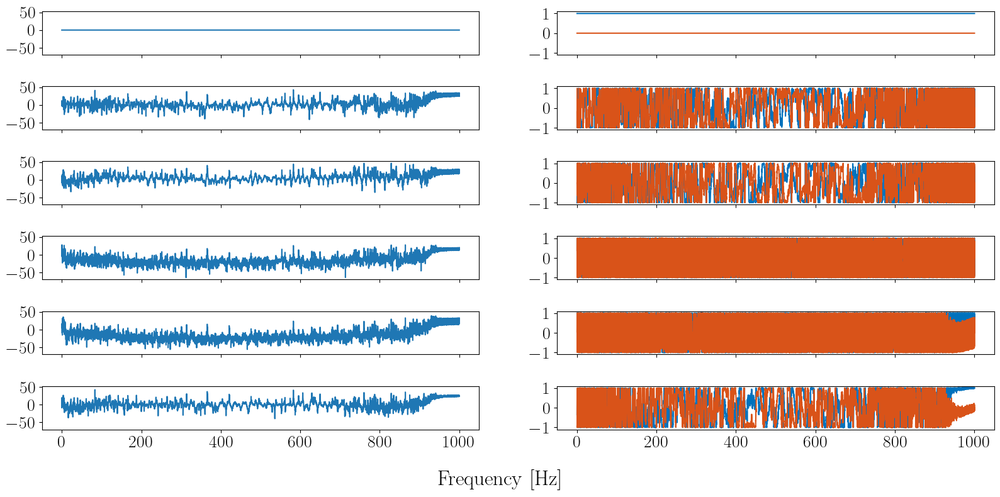

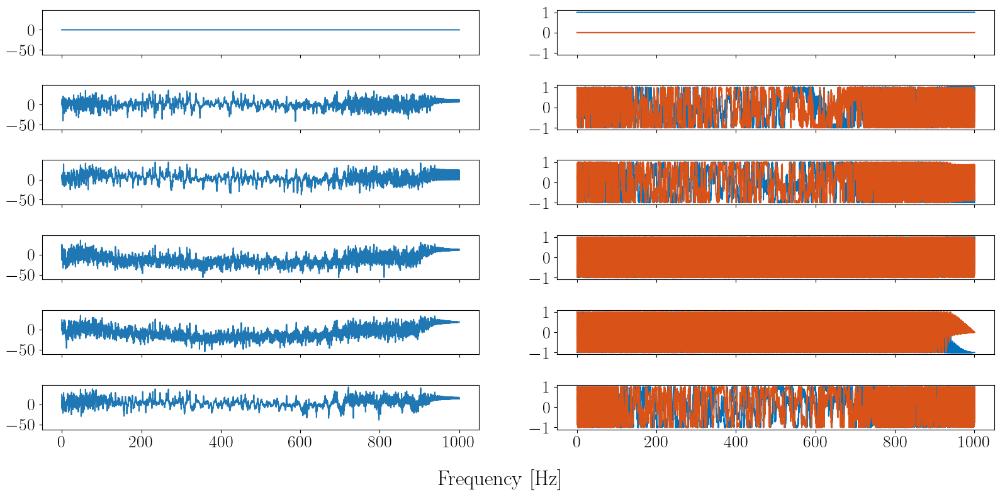

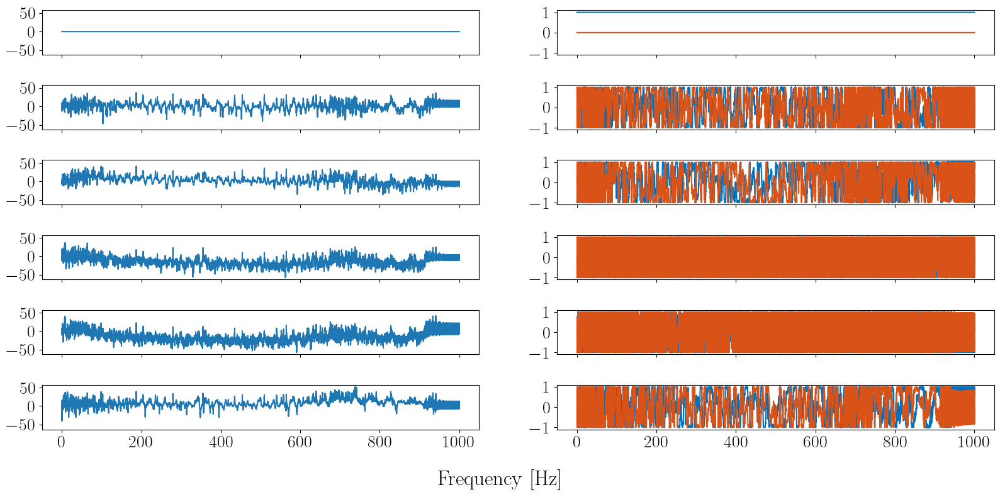

In [13]:
ref_rcv_id = "obs1"

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    ds_feature_section = ds_feature_section.isel(src_datetime=0)

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref
    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=2, figsize=(16, 8), sharex=True, sharey="col")

    for i_rcv, rcv_id_i in enumerate(obs_ids):

        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij.values / sjj.values
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        # gamma_ij.plot(ax=axs[i_rcv, 0])
        axs[i_rcv, 0].plot(sij.freq, gamma_ij)

        # DCF (sxy SCOT)
        dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
        # np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
        # np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))
        axs[i_rcv, 1].plot(sij.freq, np.real(dcf_ij), color=color(0))
        axs[i_rcv, 1].plot(sij.freq, np.imag(dcf_ij), color=color(1))

    for ax in axs.flatten():
        ax.set_title("")
        ax.set_xlabel("")
        ax.set_ylabel("")

    fig.supxlabel("Frequency [Hz]")

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


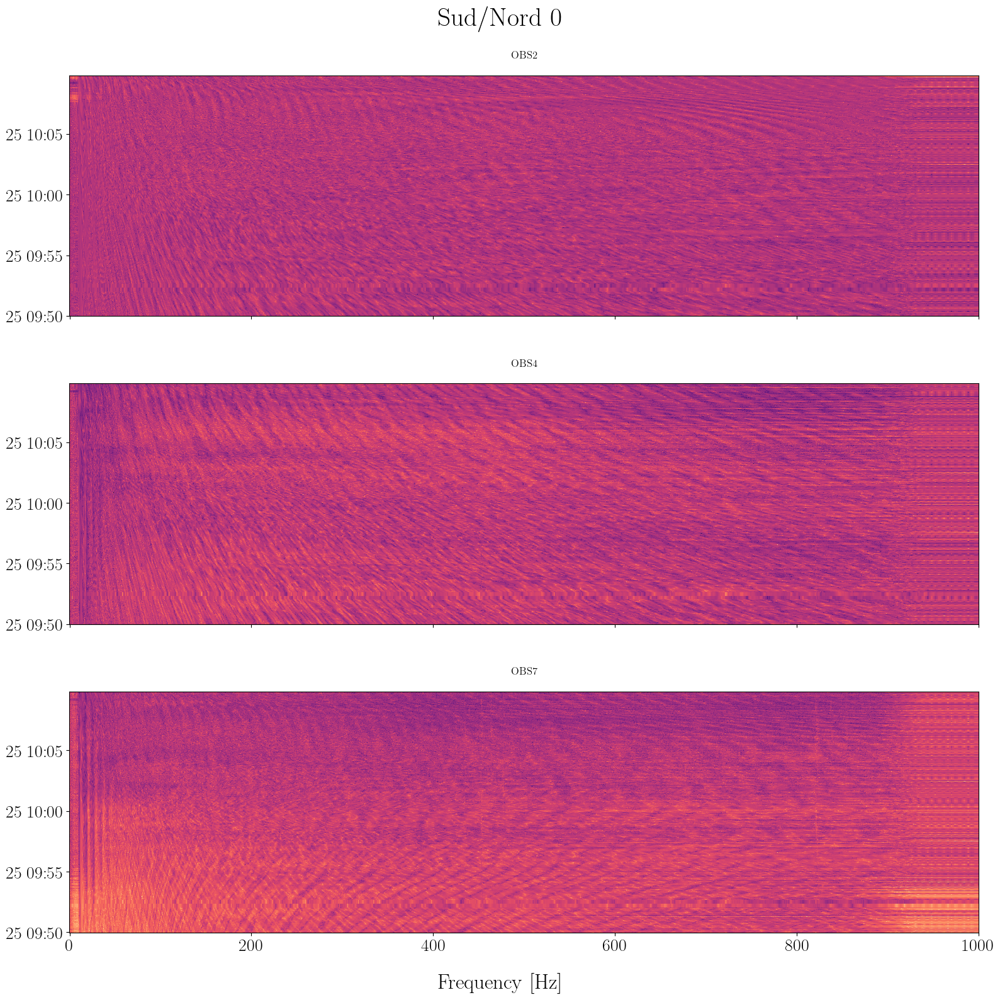

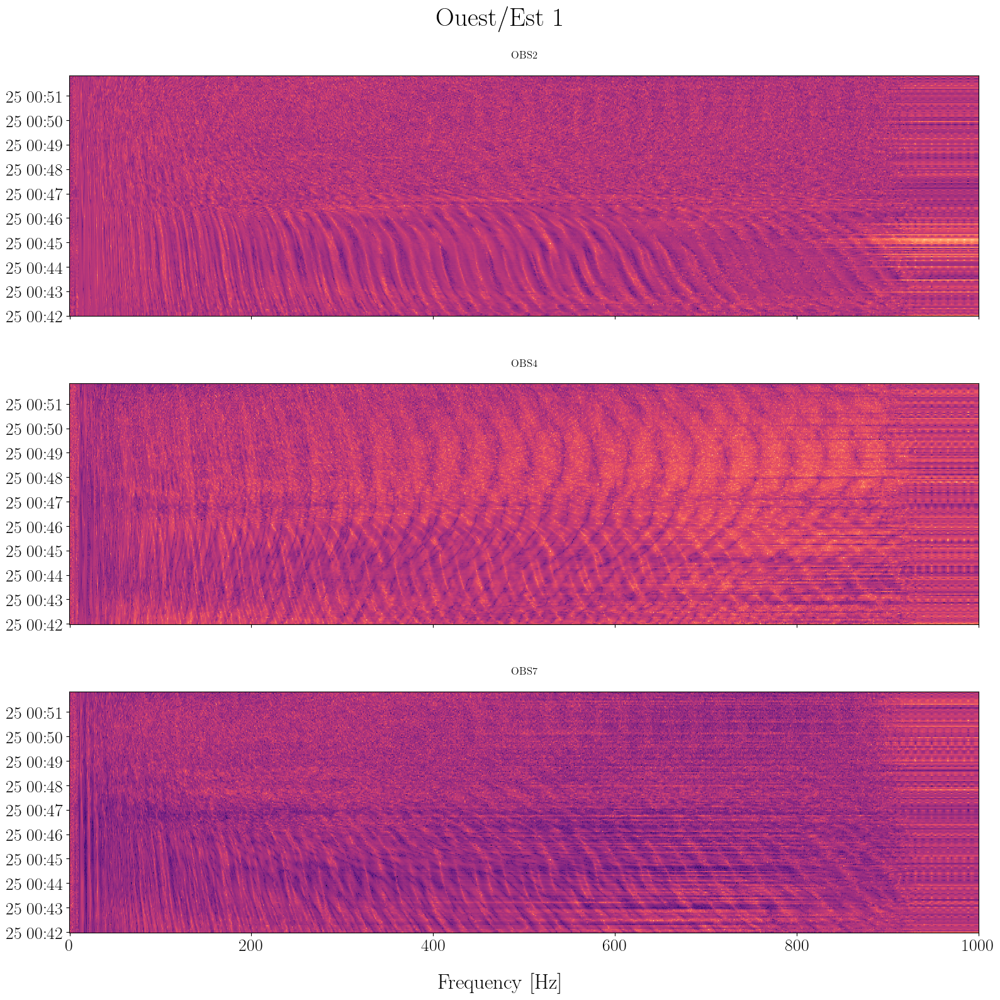

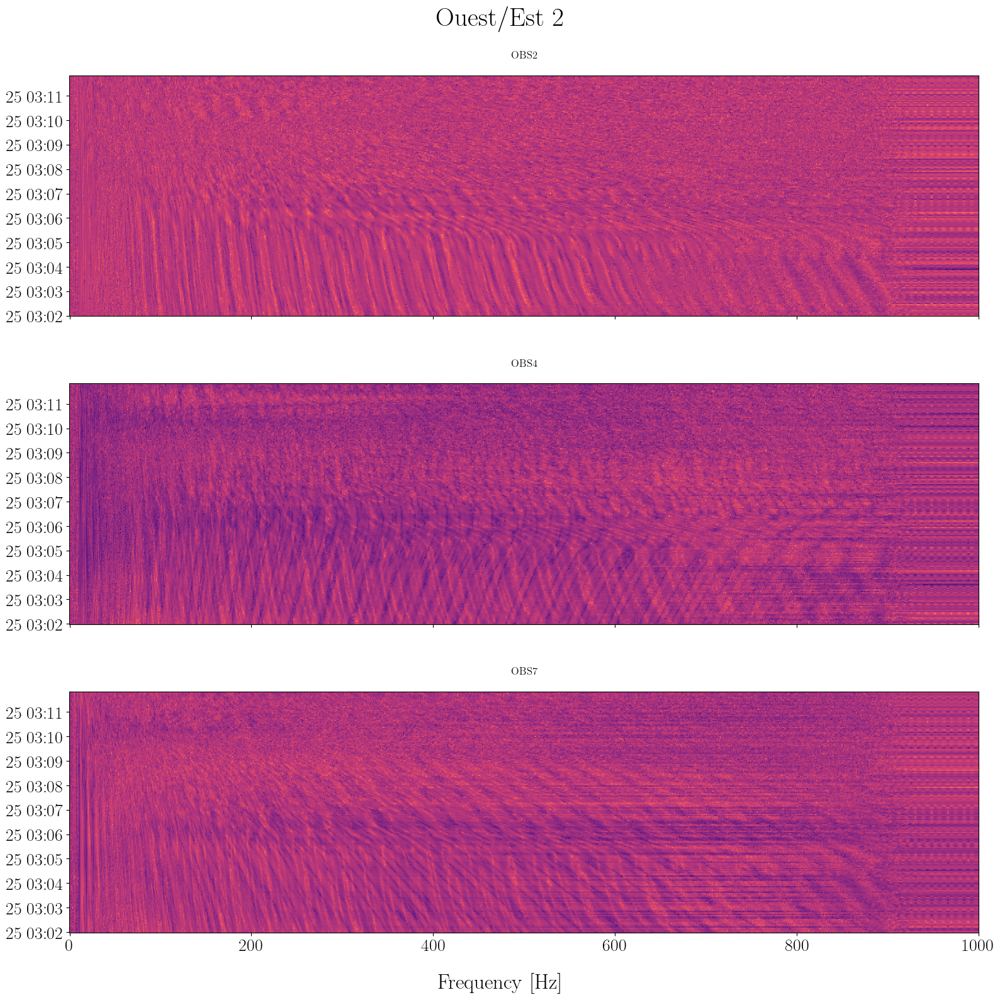

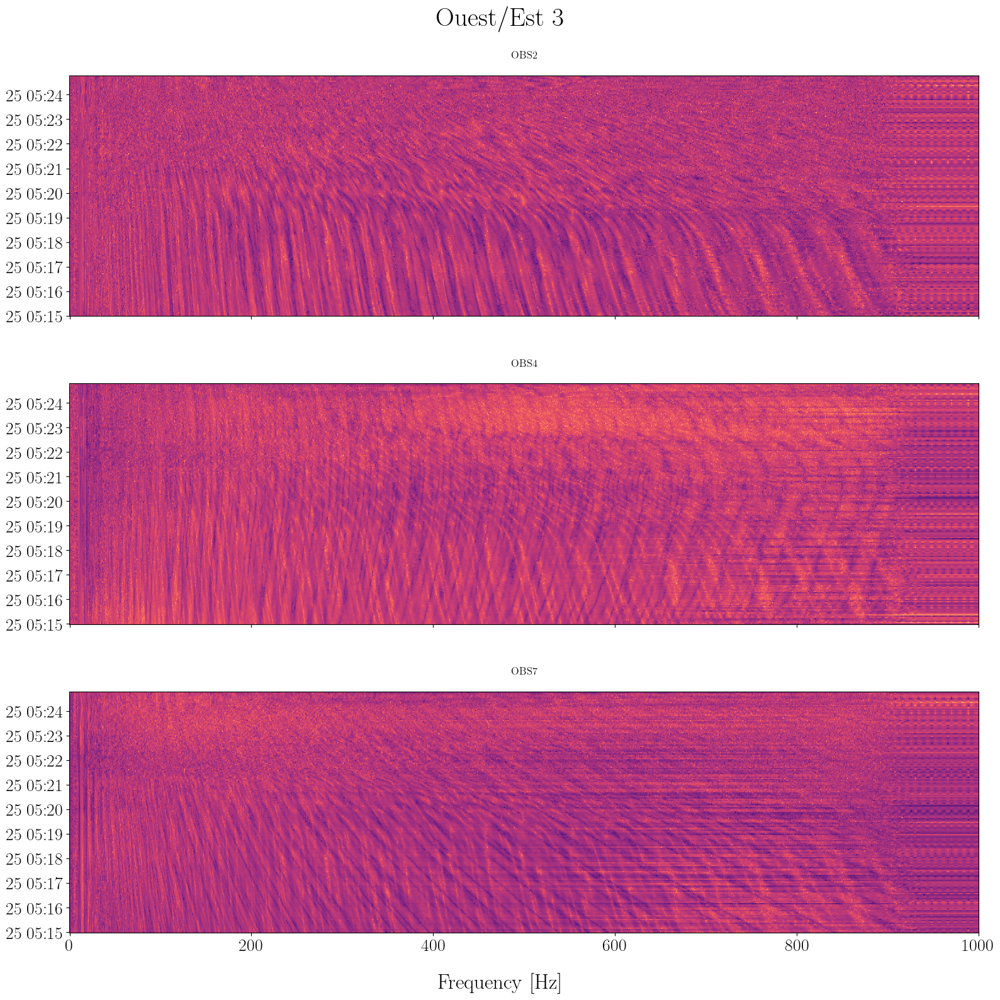

In [14]:
ref_rcv_id = "obs1"
obs_ids_visu = obs_ids[[0, 1, 2, -1]]

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref

    fig, axs = plt.subplots(
        nrows=obs_ids_visu.size-1, ncols=1, figsize=(16, 16), sharex=True, sharey=True
    )
    axs = axs.flatten()
    iplot = 0
    for i_rcv, rcv_id_i in enumerate(obs_ids_visu):

        if rcv_id_i == ref_rcv_id:
            continue
        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij.values / sjj.values
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        # gamma_ij.plot(x="freq", ax=axs[iplot], cmap="magma", add_colorbar=False)
        axs[iplot].pcolormesh(sij.freq, sij.src_datetime, gamma_ij, cmap="magma")

        axs[iplot].set_xlabel("")
        axs[iplot].set_ylabel("")
        # axs[iplot].set_title("")
        axs[iplot].set_title(rcv_id_i.upper(), fontsize=12)
        iplot += 1

    fig.supxlabel("Frequency [Hz]")
    fig.suptitle(
        f"{ds_feature_section.section_orientation} {ds_feature_section.section_id}"
    )
    # plt.xlim(100, 200)
    plt.show()

    # # DCF (sxy SCOT)
    # dcf_ij = sij / np.sqrt(sii * sjj)
    # np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
    # np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))

    # for ax in axs.flatten():
    #     ax.set_title("")
    #     ax.set_xlabel("")
    #     ax.set_ylabel("")

    # fig.supxlabel("Frequency [Hz]")

# Etude des intersections 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

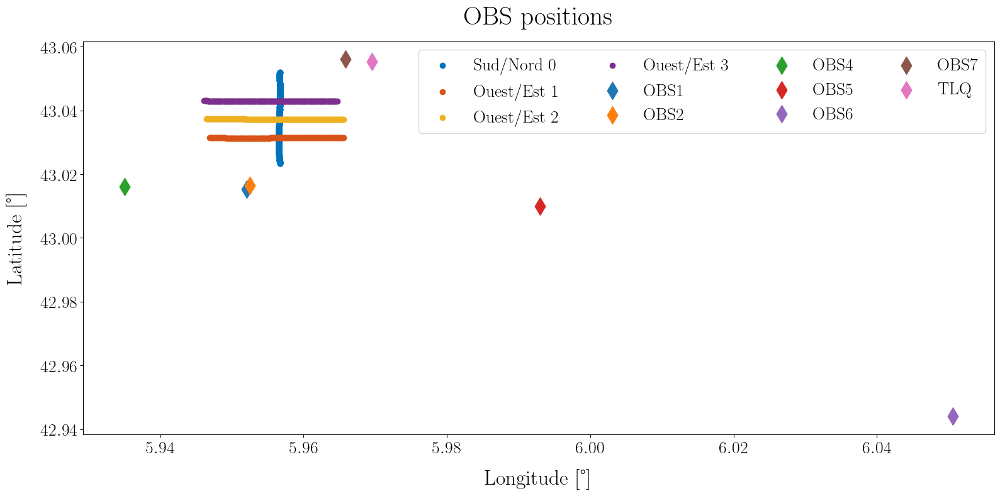

In [15]:
plot_portion_tir_pos(portion_tree=portion)

## Sud/Nord 0 - Ouest/Est 1

In [16]:
section_1_name = "sn1"
section_2_name = "oe1"
ds_feature_section1 = portion.feature[section_1_name].to_dataset()
ds_feature_section2 = portion.feature[section_2_name].to_dataset()

### CPA 

In [17]:
dist_12 = get_distance_between_sections(ds_feature_section1, ds_feature_section2)

In [18]:
# from pyproj import Geod

# geod = Geod(ellps="WGS84")

# src_lon1, src_lat1 = (
#     ds_feature_section1.tir_src_lon,
#     ds_feature_section1.tir_src_lat,
# )
# src_lon2, srcv_lat2 = (
#     ds_feature_section2.tir_src_lon,
#     ds_feature_section2.tir_src_lat,
# )

# dist_12 = []
# for i in range(src_lon2.sizes["src_datetime"]):

#     # Cast to src pos shape
#     lon2 = np.ones(src_lon1.size) * src_lon2.isel(src_datetime=i).values
#     lat2 = np.ones(src_lon1.size) * srcv_lat2.isel(src_datetime=i).values

#     # Compute geodesic distance
#     fwd_az, back_az, horiz_d = geod.inv(
#         lons1=src_lon1.values, lats1=src_lat1.values, lons2=lon2, lats2=lat2
#     )

#     dist_12.append(horiz_d)

# dist_12 = np.asarray(dist_12)

### Distance dans l'espace des données 

In [19]:
rcv_id_i = "obs4"
ref_rcv_id = "obs1"

fmin = 5
fmax = 50

pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
    ds_feature_section=ds_feature_section1,
    fmin=fmin,
    fmax=fmax,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)
pi_ij_b, gamma_b, sij_scot_b = derive_section_features(
    ds_feature_section=ds_feature_section2,
    fmin=fmin,
    fmax=fmax,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)

features_section1 = dict(pi_ij=pi_ij_a, gamma_ij=gamma_a, sij_scot=sij_scot_a)
features_section2 = dict(pi_ij=pi_ij_b, gamma_ij=gamma_b, sij_scot=sij_scot_b)

dist_theta, dist_theta_gamma, dist_L2_gamma, dist_dcf = (
    derive_feature_distance_between_sections(features_section1, features_section2)
)

In [20]:
xmin, ymin = find_min_distance_position(dt1=ds_feature_section1.src_datetime, dt2=ds_feature_section2.src_datetime, dist=dist_12)

# Theta with pi
xmin_theta, ymin_theta = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_theta.T,
)

# Theta with gamma
xmin_theta_gamma, ymin_theta_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_theta_gamma.T,
)

# L2 with gamma
xmin_L2_gamma, ymin_L2_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_L2_gamma.T,
)

# DCF
xmin_dcf, ymin_dcf = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_dcf.T,
)

In [21]:
# rcv_id_i = "obs4"
# ref_rcv_id = "obs1"

# fmin = 5
# fmax = 50

# ########################################
# # RTF
# ########################################

# ### Section 1 ###
# sjj = ds_feature_section1.sel(
#     rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# # Sij
# sij = ds_feature_section1.sel(
#     rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# pi_ij_a = sij.values / sjj.values
# pi_a = pi_ij_a[:, np.newaxis, :]  # (nt1, 1, nf)
# gamma_a = 20 * np.log10(np.abs(pi_ij_a))  # (nt1, nf)
# gamma_a = gamma_a[:, np.newaxis, :]     # (nt1, 1, nf)

# ### Section 2 ###
# sjj = ds_feature_section2.sel(
#     rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# # Sij
# sij = ds_feature_section2.sel(
#     rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy

# pi_ij_b = sij.values / sjj.values
# pi_b = pi_ij_b[np.newaxis, :, :]  # (1, nt2, nf)
# gamma_b = 20 * np.log10(np.abs(pi_ij_b))  # (nt2, nf)
# gamma_b = gamma_b[np.newaxis, :, :]     # (1, nt2, nf)

# # Compute theta with pi
# inner_prod = np.nansum(pi_a * np.conj(pi_b), axis=-1)
# norm_a = np.sqrt(np.nansum(pi_a * np.conj(pi_a), axis=-1))
# norm_b = np.sqrt(np.nansum(pi_b * np.conj(pi_b), axis=-1))
# # Clip to [0, 1] for stability
# cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
# dist_theta = 1 - cos_angle  #  to [0, 1]

# # Compute L2 with gamma
# dist_L2_gamma = np.sqrt(np.nansum(np.abs(gamma_a - gamma_b) ** 2, axis=-1))
# dist_L2_gamma = dist_L2_gamma / np.nanmax(dist_L2_gamma)  # Normalize to [0, 1]

# # Compute theta with gamma
# inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
# norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
# norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# # Clip to [-1, 1] for stability
# cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
# dist_theta_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]


# ########################################
# # DCF
# ########################################

# ### Section 1 ###
# # Sii
# sii = ds_feature_section1.sel(
#     rcv_i=rcv_id_i, rcv_j=rcv_id_i, freq=slice(fmin, fmax)
# ).Sxy
# # Sjj
# sjj = ds_feature_section1.sel(
#     rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# # Sij
# sij = ds_feature_section1.sel(
#     rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# sij_scot_a = sij.values / np.sqrt(sii.values * sjj.values)
# sij_scot_a = sij_scot_a[:, np.newaxis, :]  # (nt1, 1, nf)

# ### Section 2 ###
# # Sii
# sii = ds_feature_section2.sel(
#     rcv_i=rcv_id_i, rcv_j=rcv_id_i, freq=slice(fmin, fmax)
# ).Sxy
# # Sjj
# sjj = ds_feature_section2.sel(
#     rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# # Sij
# sij = ds_feature_section2.sel(
#     rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
# ).Sxy
# sij_scot_b = sij.values / np.sqrt(sii.values * sjj.values)
# sij_scot_b = sij_scot_b[np.newaxis, :, :]  # (1, nt2, nf)

# # DCF
# dist_dcf = np.abs(
#     np.nansum(
#         sij_scot_a * np.conj(sij_scot_b),
#         axis=-1,
#     )
# )
# dist_dcf = 1 - dist_dcf / (np.sqrt(np.nansum(np.abs(sij_scot_a) ** 2, axis=-1)) * np.sqrt(np.nansum(np.abs(sij_scot_b) ** 2, axis=-1)))

In [22]:
# ind_min_dist = np.argmin(dist_12)
# xx, yy = np.meshgrid(src_lon1.src_datetime, src_lon2.src_datetime)
# xmin, ymin = xx.flatten()[ind_min_dist], yy.flatten()[ind_min_dist]

# # Theta with pi
# ind_min_theta = np.argmin(dist_theta.T)
# xmin_theta, ymin_theta = xx.flatten()[ind_min_theta], yy.flatten()[ind_min_theta]

# # Theta with gamma
# ind_min_theta_gamma = np.argmin(dist_theta_gamma.T)
# xmin_theta_gamma, ymin_theta_gamma = (
#     xx.flatten()[ind_min_theta_gamma],
#     yy.flatten()[ind_min_theta_gamma],
# )

# # L2 with gamma
# ind_min_L2_gamma = np.argmin(dist_L2_gamma.T)
# xmin_L2_gamma, ymin_L2_gamma = (
#     xx.flatten()[ind_min_L2_gamma],
#     yy.flatten()[ind_min_L2_gamma],
# )

# # DCF 
# ind_min_dcf = np.argmin(dist_dcf.T)
# xmin_dcf, ymin_dcf = xx.flatten()[ind_min_dcf], yy.flatten()[ind_min_dcf]

#### R vs theta 

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

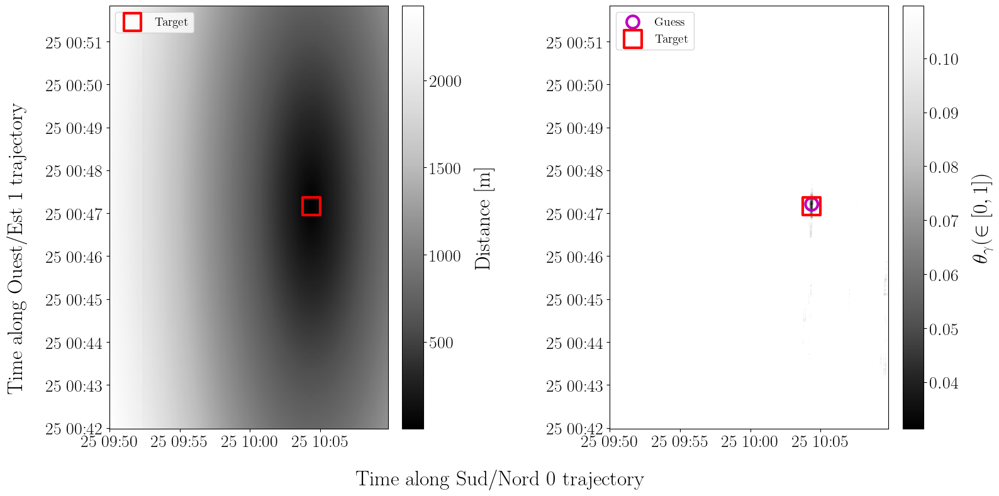

In [23]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_12,
    cmap="Grays_r",
)
plt.colorbar(im, ax=axs[0], label="Distance [m]")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta_{\gamma} (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ 

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

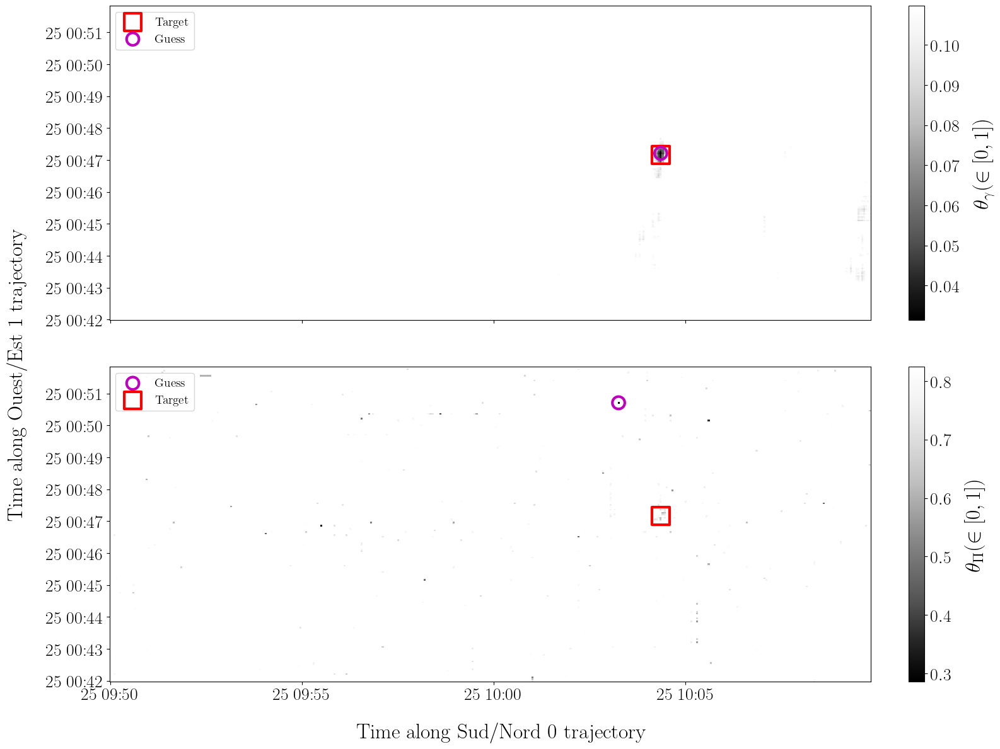

In [24]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta_{\Pi} (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ vs $L2_{\gamma}$

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

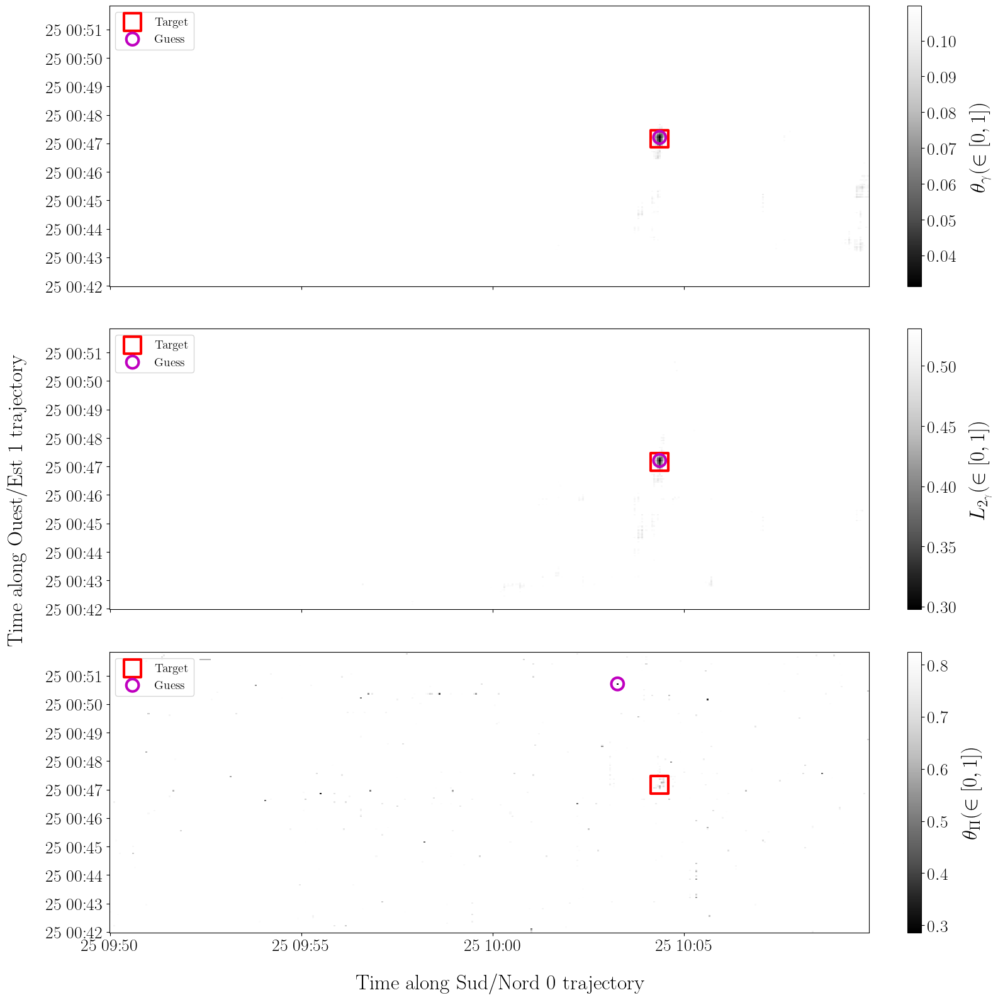

In [25]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")

im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_L2_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_L2_gamma, 0.1),
    vmin=np.nanmin(dist_L2_gamma),
    vmax=np.nanpercentile(dist_L2_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\gamma}} (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")


axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_L2_gamma,
    ymin_L2_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)


for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

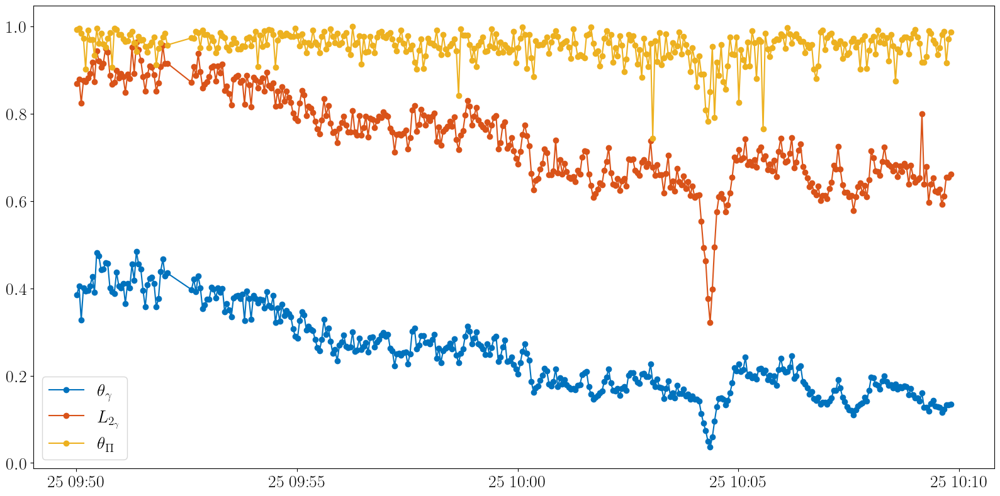

In [26]:
idx_ymin_theta_gamma = np.abs(ds_feature_section2.src_datetime - ymin_theta_gamma).argmin(dim="src_datetime")
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin).argmin(dim="src_datetime")
line_theta_gamma = dist_theta_gamma[:, idx_ymin]

# idx_ymin_theta = np.abs(src_lon2.src_datetime - ymin_theta).argmin(dim="src_datetime")
line_theta = dist_theta[:, idx_ymin]

# idx_ymin_L2_gamma = np.abs(src_lon2.src_datetime - ymin_L2_gamma).argmin(dim="src_datetime")
line_L2_gamma = dist_L2_gamma[:, idx_ymin]

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(ds_feature_section1.src_datetime, line_L2_gamma, "-o", color=color(1), label=r"$L_{2_{\gamma}}$")
plt.plot(ds_feature_section1.src_datetime, line_theta, "-o", color=color(2), label=r"$\theta_{\Pi}$")
plt.legend()

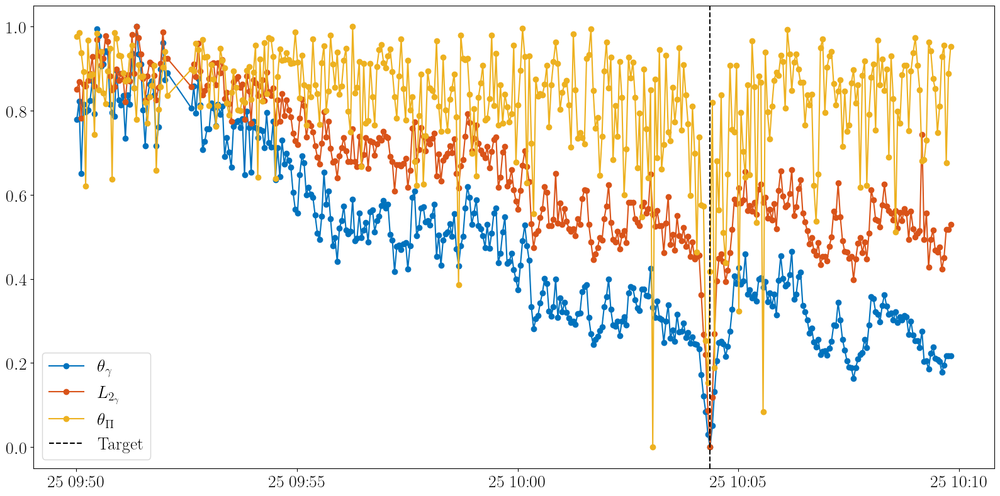

In [27]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma))
line_theta = (line_theta - np.nanmin(line_theta)) / (np.nanmax(line_theta) - np.nanmin(line_theta))
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma))

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()

Les trois distances présentent un minimum à la position attendue. Comme précédemment observé, le domaine de monotonie est très faible quelle que soit la distance ! 

(np.float64(20509.419000001133), np.float64(20509.420388890023))

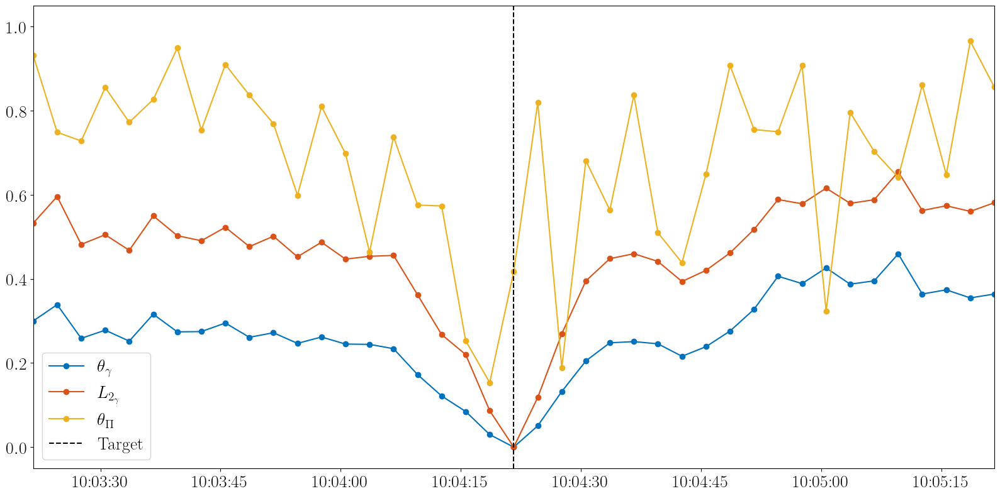

In [28]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (
    np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma)
)
line_theta = (line_theta - np.nanmin(line_theta)) / (
    np.nanmax(line_theta) - np.nanmin(line_theta)
)
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (
    np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma)
)

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()
plt.xlim(xmin - np.timedelta64(60, "s"), xmin + np.timedelta64(60, "s"))

### Comparaison à la méthode DCF 

#### R vs dcf

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

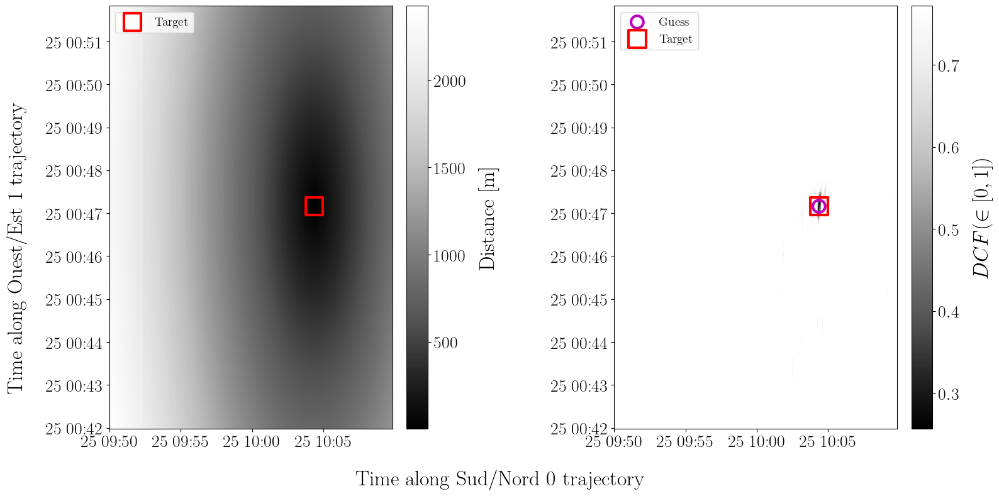

In [29]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_12,
    cmap="Grays_r",
)
plt.colorbar(im, ax=axs[0], label="Distance [m]")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_dcf),
    vmax=np.nanpercentile(dist_dcf, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs DCF 

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

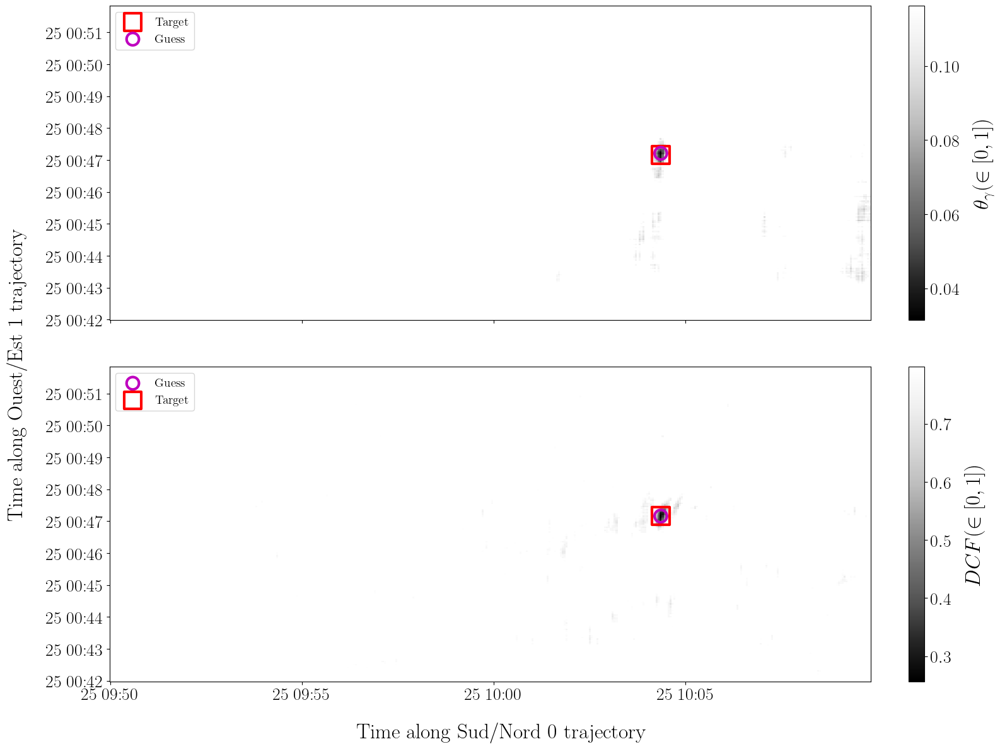

In [30]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.75), np.nanpercentile(dist_dcf, 0.75))


fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_dcf),
    vmax=np.nanpercentile(dist_dcf, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

# Common colorbar
# plt.colorbar(im, ax=axs, label="Distance")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

Afin de comparer les deux approches on normalise afin d'avoir des variations dans la pleine échelle [0, 1]

In [31]:
dist_dcf_norm = (dist_dcf - np.nanmin(dist_dcf)) / (np.nanmax(dist_dcf) - np.nanmin(dist_dcf))
dist_theta_gamma_norm = (dist_theta_gamma - np.nanmin(dist_theta_gamma)) / (np.nanmax(dist_theta_gamma) - np.nanmin(dist_theta_gamma))

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

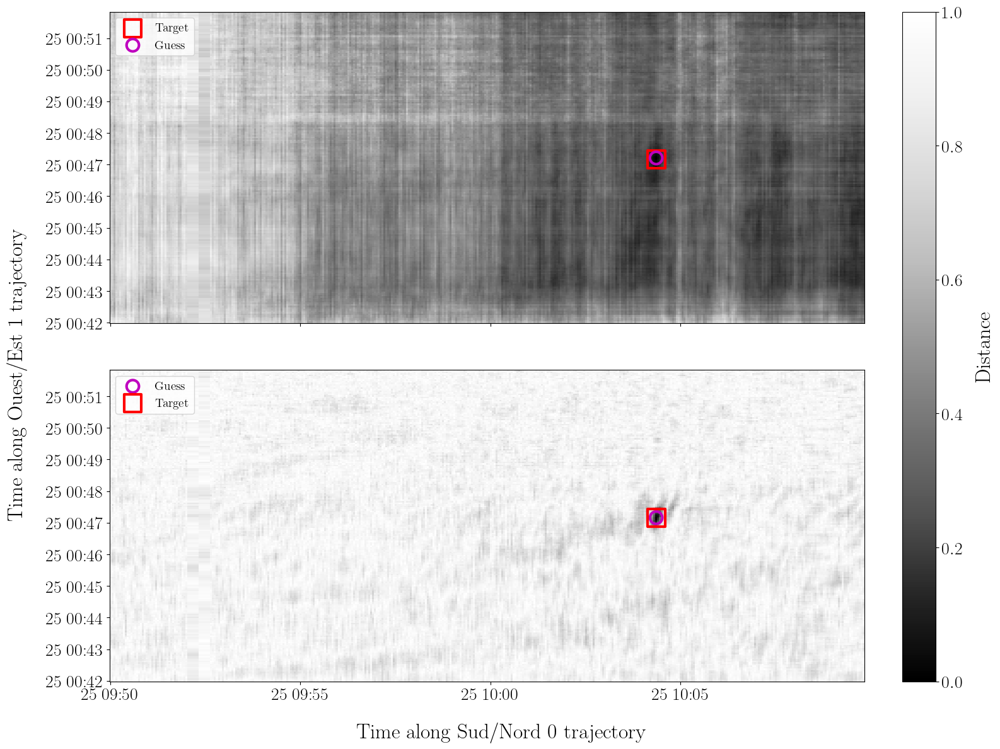

In [32]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.5), np.nanpercentile(dist_dcf, 0.5))

vmin = 0
vmax = 1

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma_norm.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    # vmin=np.nanmin(dist_theta_gamma),
    # vmax=np.nanpercentile(dist_theta_gamma, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf_norm.T,
    cmap="Grays_r",
    # vmin=np.nanmin(dist_dcf),
    # vmax=np.nanpercentile(dist_dcf, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

# Common colorbar
plt.colorbar(im, ax=axs, label="Distance")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

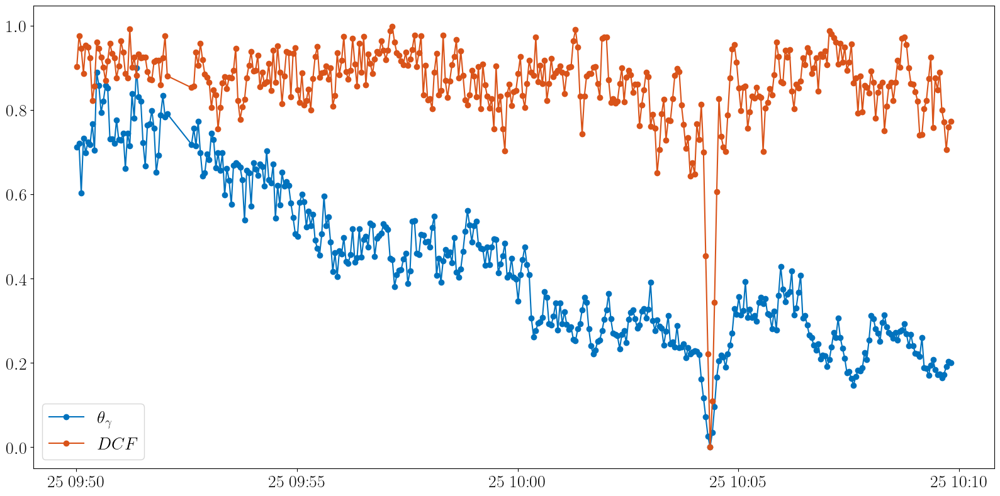

In [33]:
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin_theta_gamma).argmin(dim="src_datetime")
line_theta_gamma_norm = dist_theta_gamma_norm[:, idx_ymin]
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin_dcf).argmin(dim="src_datetime")
line_dcf_norm = dist_dcf_norm[:, idx_ymin]

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma_norm,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_dcf_norm,
    "-o",
    color=color(1),
    label=r"$DCF$",
)

plt.legend()

Ce n'est pas une bonne manière de comparer les deux résultats : dans le cas où l'un des deux OBS du couple est distant de l'OBS de référence theta croît avec la distance au point d'intersection et la normalisation dépend donc de la taille du domaine que l'on regarde. Plus le domaine est grand plus le contraste au point d'intersection va dimuner par normalisation.

### Hypothèse de variété  

In [34]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

# ISOMAP
n_components = 100
n_neighbors = 5
p = 2

# Define isomap object
# With Minkowski distance (equivalent to euclidean distance for p = 2)
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    # p=p,
    metric="precomputed",
)
# # With cosine distance
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors,
#     n_components=n_components,
#     metric="cosine"
# )

# Build data
data = np.concatenate(
    [gamma_a.squeeze(), gamma_b.squeeze()], axis=0
)  # (n_sample, n_features) = (nt1 + nt2, nfreq)

# Compute theta with gamma
data_a = data[:, np.newaxis, :]
data_b = data[np.newaxis, :, :]
inner_prod = np.nansum(data_a * data_b, axis=-1)
norm_a = np.sqrt(np.nansum(data_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(data_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_data = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1] -> shape (nt1 + nt2, nt1 + nt2)


# Learn manifold and project data in target dimension
# Project
coords = isomap_obj.fit_transform(dist_data)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

Text(0, 0.5, 'Replica index')

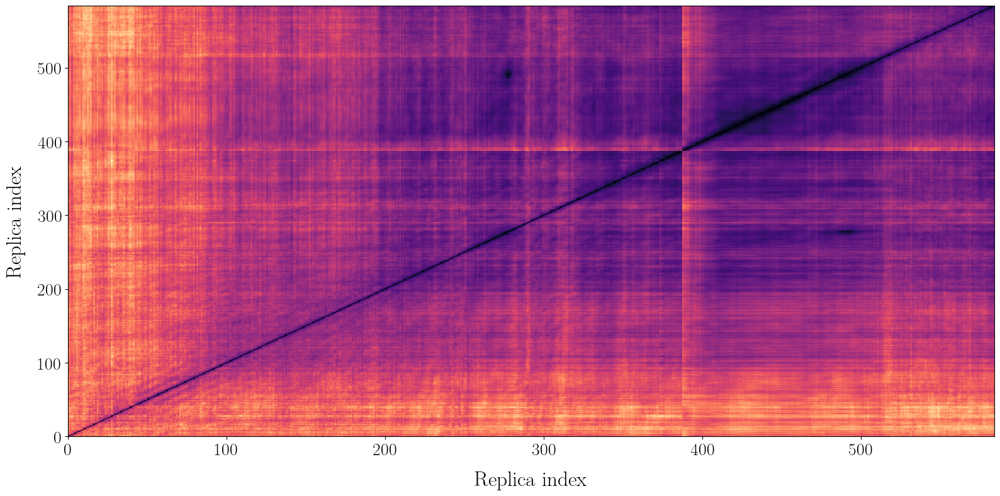

In [35]:
plt.figure()
plt.pcolormesh(dist_data, cmap="magma")
plt.xlabel("Replica index")
plt.ylabel("Replica index")

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_16000\606414193.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


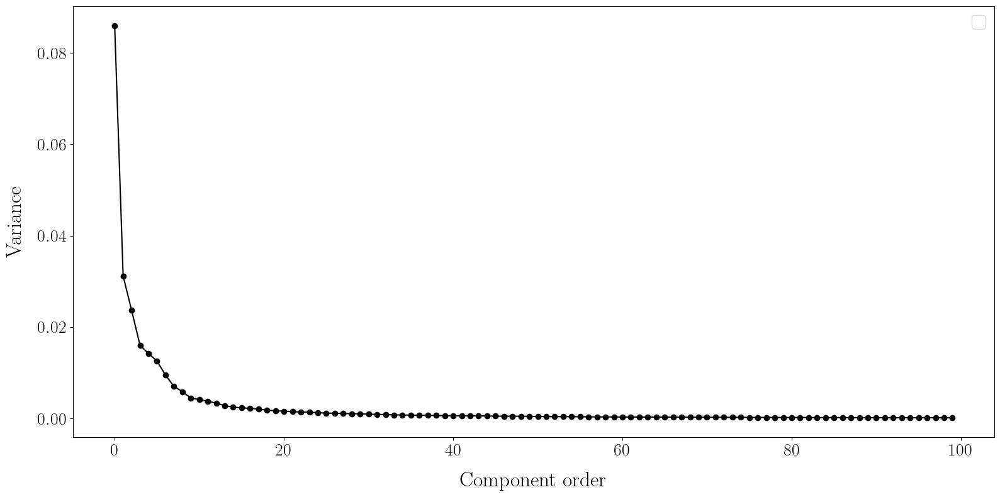

In [36]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()
# plt.ylim(0, 0.05)

In [37]:
# dist_low_dim = np.sqrt(np.nansum((coords[:, np.newaxis, :] - coords[np.newaxis, :, :]) ** 2, axis=-1))

low_dim = 5
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

# Split back into section 1 and section 2
coords_low_dim_a = coords_low_dim[: gamma_a.shape[0], :]
coords_low_dim_b = coords_low_dim[gamma_a.shape[0]:, :]

# Compute L2 distance in low dimension
dist_low_dim = np.sqrt(
    np.nansum((coords_low_dim_a[:, np.newaxis, :] - coords_low_dim_b[np.newaxis, :, :]) ** 2, axis=-1)
)

xmin_low_dim, ymin_low_dim = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_low_dim.T,
)

# ind_min_low_dim = np.argmin(dist_low_dim.T)
# xmin_low_dim, ymin_low_dim = xx.flatten()[ind_min_low_dim], yy.flatten()[ind_min_low_dim]

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

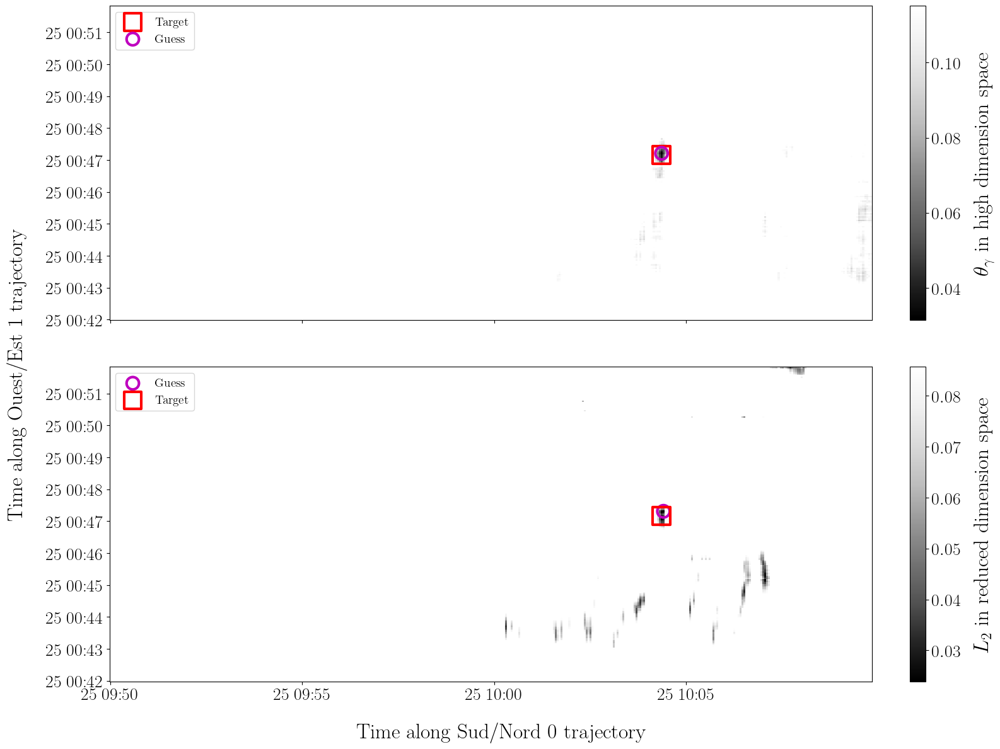

In [38]:
# Plot to compare with dist_theta_gamma and dist_dcf

# # vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# # vmax = min(np.nanpercentile(dist_theta_gamma, 0.5), np.nanpercentile(dist_dcf, 0.5))

# vmin = 0
# vmax = 1

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.9),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma}$ in high dimension space")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_low_dim.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_low_dim),
    vmax=np.nanpercentile(dist_low_dim, 0.9),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[1], label=r"$L_2$ in reduced dimension space")

# Common colorbar
# plt.colorbar(im, ax=axs, label="Distance")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_low_dim,
    ymin_low_dim,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### Influence du nombre de composantes

Reduction to 1 dimensions, percentage of reduction = 99.86%
Reduction to 2 dimensions, percentage of reduction = 99.73%
Reduction to 3 dimensions, percentage of reduction = 99.59%
Reduction to 4 dimensions, percentage of reduction = 99.46%
Reduction to 5 dimensions, percentage of reduction = 99.32%
Reduction to 6 dimensions, percentage of reduction = 99.19%
Reduction to 7 dimensions, percentage of reduction = 99.05%
Reduction to 8 dimensions, percentage of reduction = 98.92%
Reduction to 9 dimensions, percentage of reduction = 98.78%
Reduction to 10 dimensions, percentage of reduction = 98.64%


Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

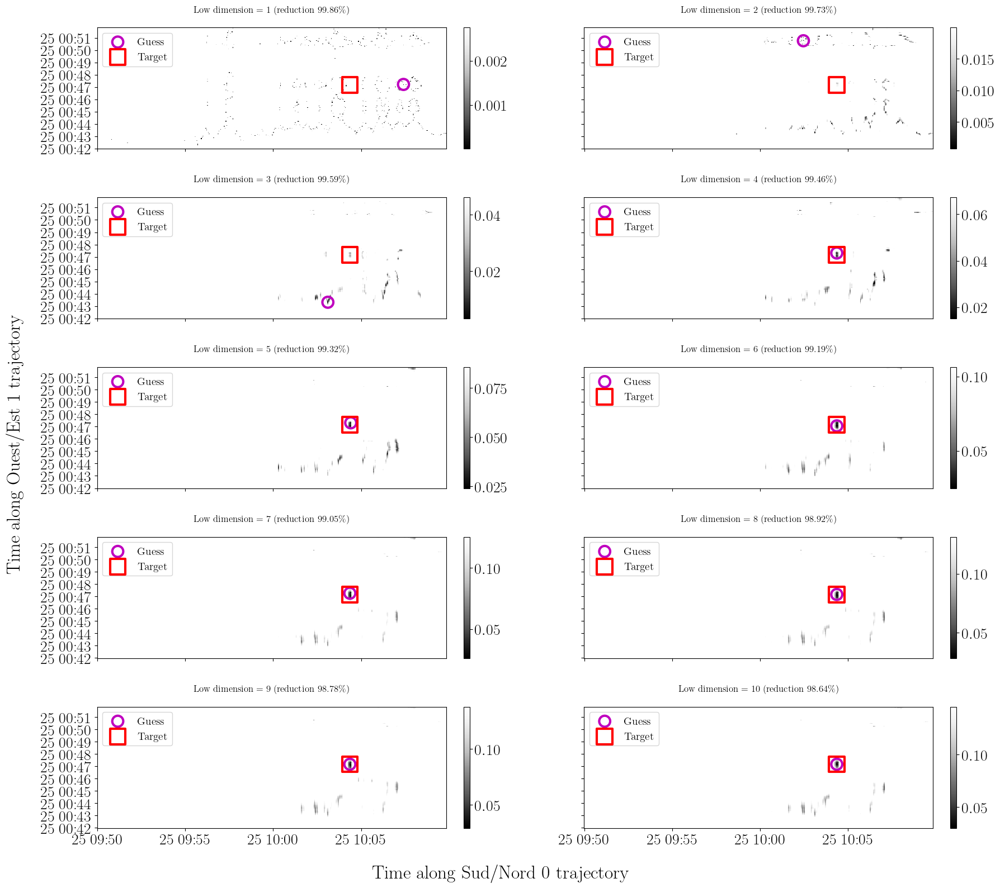

In [39]:
fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(18, 16), sharex=True, sharey=True)
axs = axs.flatten()
i = 0
for low_dim in range(1, 11):

    dim_red = 100 * (1 - low_dim / gamma_a.shape[-1])
    print(
        f"Reduction to {low_dim} dimensions, percentage of reduction = {dim_red:.2f}%"
    )
    coords_low_dim = coords[:, :low_dim]
    coords_low_dim.shape

    # Split back into section 1 and section 2
    coords_low_dim_a = coords_low_dim[: gamma_a.shape[0], :]
    coords_low_dim_b = coords_low_dim[gamma_a.shape[0] :, :]

    # Compute L2 distance in low dimension
    dist_low_dim = np.sqrt(
        np.nansum(
            (coords_low_dim_a[:, np.newaxis, :] - coords_low_dim_b[np.newaxis, :, :]) ** 2,
            axis=-1,
        )
    )

    # ind_min_low_dim = np.argmin(dist_low_dim.T)
    # xmin_low_dim, ymin_low_dim = (
    #     xx.flatten()[ind_min_low_dim],
    #     yy.flatten()[ind_min_low_dim],
    # )
    xmin_low_dim, ymin_low_dim = find_min_distance_position(
        dt1=ds_feature_section1.src_datetime,
        dt2=ds_feature_section2.src_datetime,
        dist=dist_low_dim.T,
    )

    # Plot
    im = axs[i].pcolormesh(
        ds_feature_section1.src_datetime,
        ds_feature_section2.src_datetime,
        dist_low_dim.T,
        cmap="Grays_r",
        vmin=np.nanmin(dist_low_dim),
        vmax=np.nanpercentile(dist_low_dim, 0.9),
        # vmin=vmin,
        # vmax=vmax,
    )
    plt.colorbar(im, ax=axs[i])

    axs[i].scatter(
        xmin_low_dim,
        ymin_low_dim,
        marker="o",
        s=200,
        facecolors="none",
        edgecolors="m",
        label="Guess",
        linewidth=3,
    )
    axs[i].scatter(
        xmin,
        ymin,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="r",
        label="Target",
        linewidth=3,
    )

    axs[i].set_title(f"Low dimension = {low_dim} (reduction {dim_red:.2f}\%)", fontsize=12)

    i += 1

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

L'augmentation du nombre de composantes augemente le contraste de la surface d'ambiguité et assure l'existence d'un unique lobe principal (pas de lobes images) bien positionné. 

### Stratégie d'interpolation 

#### Cas 1D

Text(0.5, 0, 'Time along Ouest/Est 1 trajectory')

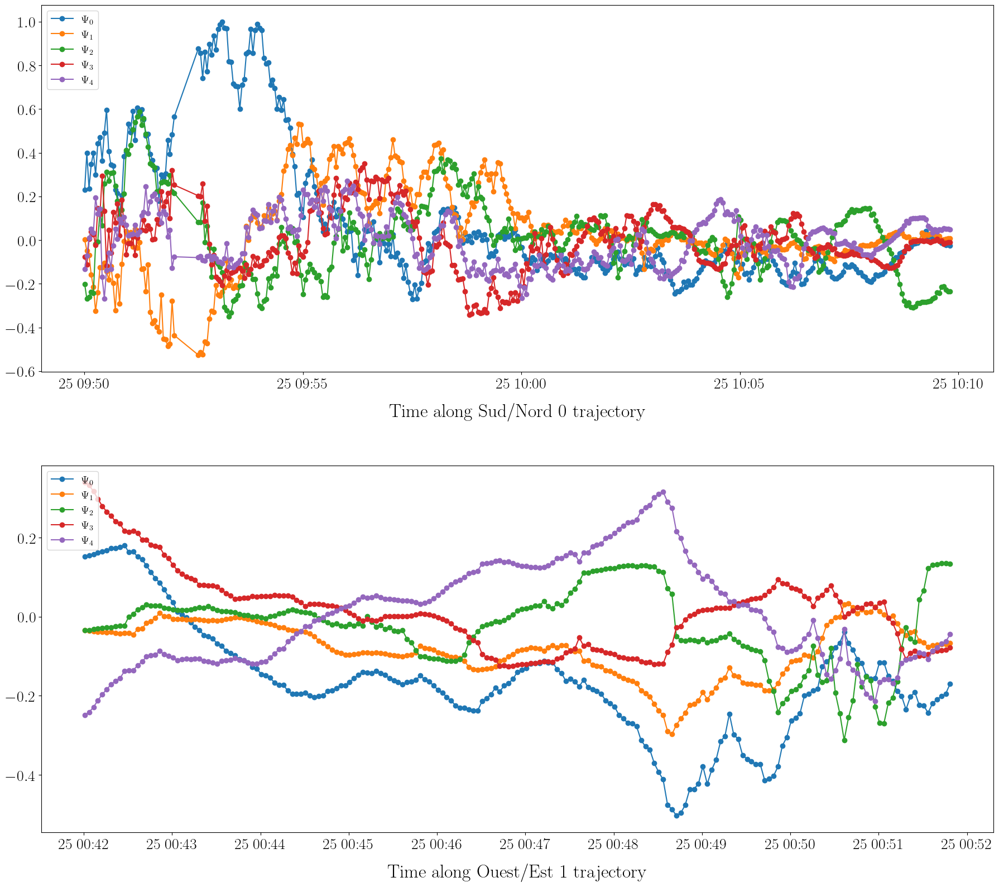

In [40]:
# Plot map of each coords
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(18, 16))
axs = axs.flatten()

for i_low_dim in range(0, 5):

    # Extract coords
    coords_low_dim_i = coords[:, i_low_dim:i_low_dim+1]

    # Split back into section 1 and section 2
    coords_low_dim_a = coords_low_dim_i[: gamma_a.shape[0], :]
    coords_low_dim_b = coords_low_dim_i[gamma_a.shape[0] :, :]

    # Plot
    axs[0].plot(
        ds_feature_section1.src_datetime,
        coords_low_dim_a,
        "-o",
        label=rf"$\Psi_{{{i_low_dim}}}$",
    )
    axs[1].plot(
        ds_feature_section2.src_datetime,
        coords_low_dim_b,
        "-o",
        label=rf"$\Psi_{{{i_low_dim}}}$",
    )

    # axs[i].set_title(
    #     f"Low dimension = {low_dim} (reduction {dim_red:.2f}\%)", fontsize=12
    # )


for ax in axs:
    ax.legend(loc="upper left", fontsize=14)

axs[0].set_xlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
axs[1].set_xlabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

# fig.supylabel(
#     f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
# )

In [41]:
# Apply interpolation before loc
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

# Split back into section 1 and section 2
coords_low_dim_a = coords_low_dim[: gamma_a.shape[0], :]
coords_low_dim_b = coords_low_dim[gamma_a.shape[0] :, :]


# Interpolate each coords sequence
interp_times1 = pd.date_range(
    start=ds_feature_section1.src_datetime.values[0],
    end=ds_feature_section1.src_datetime.values[-1],
    freq="1s",
)
times1_linear = (
    ds_feature_section1.src_datetime.values - ds_feature_section1.src_datetime.values[0]
) / np.timedelta64(1, "s")
interp_times1_linear = (interp_times1 - interp_times1[0]) / np.timedelta64(1, "s")

times2_linear = (
    ds_feature_section2.src_datetime.values - ds_feature_section2.src_datetime.values[0]
) / np.timedelta64(1, "s")
interp_times2 = pd.date_range(
    start=ds_feature_section2.src_datetime.values[0],
    end=ds_feature_section2.src_datetime.values[-1],
    freq="1s",
)
interp_times2_linear = (interp_times2 - interp_times2[0]) / np.timedelta64(1, "s")

coords_low_dim_a_interp = np.empty((interp_times1.size, coords_low_dim_a.shape[1]))
coords_low_dim_b_interp = np.empty((interp_times2.size, coords_low_dim_b.shape[1]))

for i_dim in range(coords_low_dim.shape[1]):
    # Interp psi_i_a
    coords_low_dim_a_i = coords_low_dim_a[:, i_dim]
    coords_low_dim_a_i_interp = np.interp(
        x=interp_times1_linear, xp=times1_linear, fp=coords_low_dim_a_i
    )
    coords_low_dim_a_interp[:, i_dim] = coords_low_dim_a_i_interp

    # Interp psi_i_b
    coords_low_dim_b_i = coords_low_dim_b[:, i_dim]
    coords_low_dim_b_i_interp = np.interp(
        x=interp_times2_linear, xp=times2_linear, fp=coords_low_dim_b_i
    )
    coords_low_dim_b_interp[:, i_dim] = coords_low_dim_b_i_interp

Text(0.5, 0, 'Time along Ouest/Est 1 trajectory')

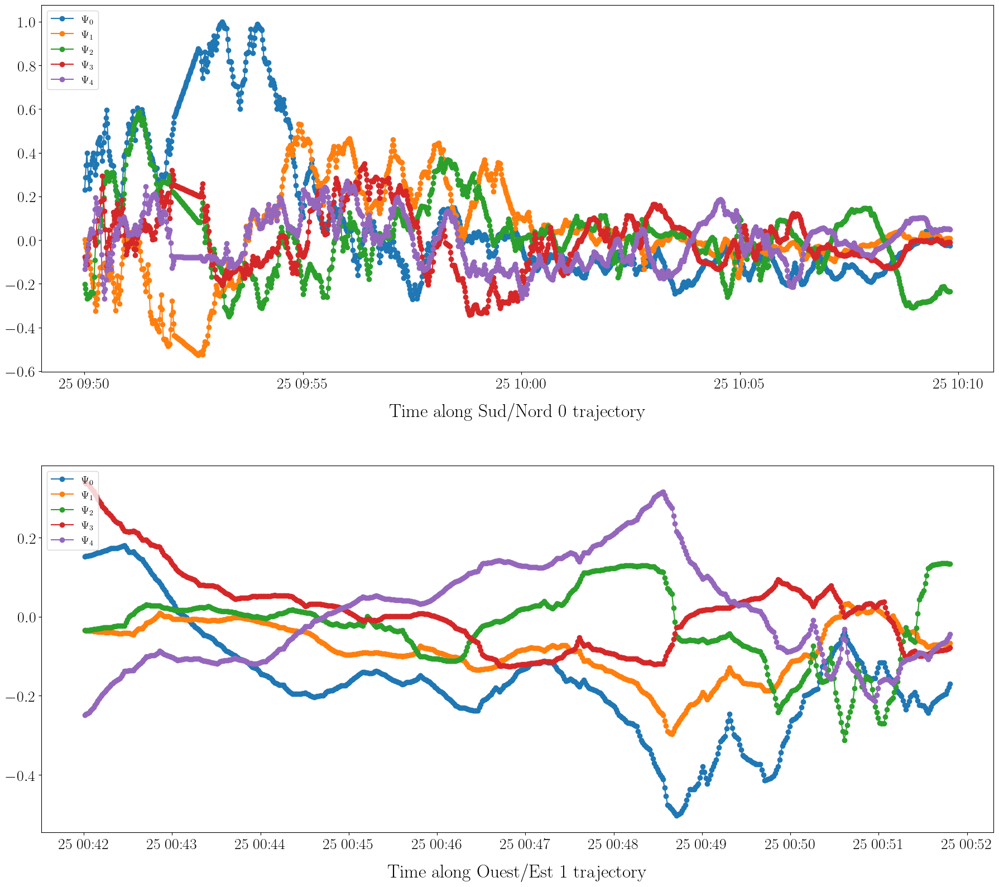

In [42]:
# Plot map of each coords
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(18, 16))
axs = axs.flatten()

for i_low_dim in range(0, 5):

    # Plot
    axs[0].plot(
        interp_times1,
        coords_low_dim_a_interp[:, i_low_dim],
        "-o",
        label=rf"$\Psi_{{{i_low_dim}}}$",
    )
    axs[1].plot(
        interp_times2,
        coords_low_dim_b_interp[:, i_low_dim],
        "-o",
        label=rf"$\Psi_{{{i_low_dim}}}$",
    )


for ax in axs:
    ax.legend(loc="upper left", fontsize=14)

axs[0].set_xlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
axs[1].set_xlabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

In [43]:
# Compute L2 distance in low dimension
dist_low_dim_interp = np.sqrt(
    np.nansum(
        (coords_low_dim_a_interp[:, np.newaxis, :] - coords_low_dim_b_interp[np.newaxis, :, :]) ** 2,
        axis=-1,
    )
)

xmin_low_dim_interp, ymin_low_dim_interp = find_min_distance_position(
    dt1=interp_times1,
    dt2=interp_times2,
    dist=dist_low_dim_interp.T,
)

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

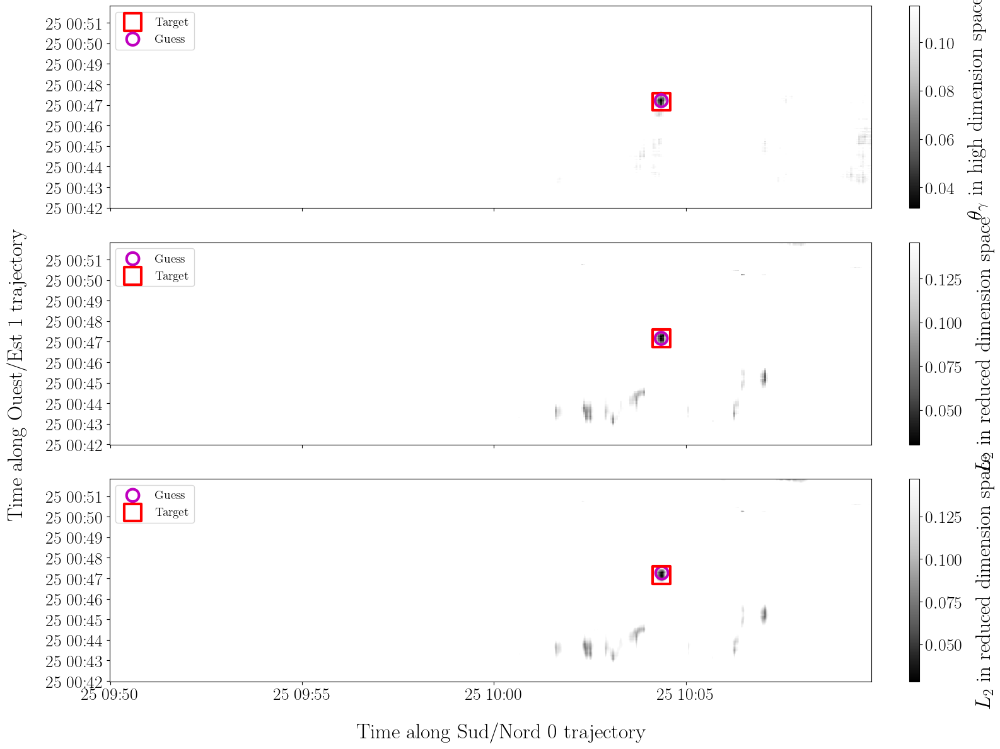

In [44]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.9),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma}$ in high dimension space")
axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_low_dim.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_low_dim),
    vmax=np.nanpercentile(dist_low_dim, 0.9),
)
plt.colorbar(im, ax=axs[1], label=r"$L_2$ in reduced dimension space")
axs[1].scatter(
    xmin_low_dim,
    ymin_low_dim,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

im = axs[2].pcolormesh(
    interp_times1,
    interp_times2,
    dist_low_dim_interp.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_low_dim_interp),
    vmax=np.nanpercentile(dist_low_dim_interp, 0.9),
)
plt.colorbar(im, ax=axs[2], label=r"$L_2$ in reduced dimension space")
axs[2].scatter(
    xmin_low_dim_interp,
    ymin_low_dim_interp,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)


for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

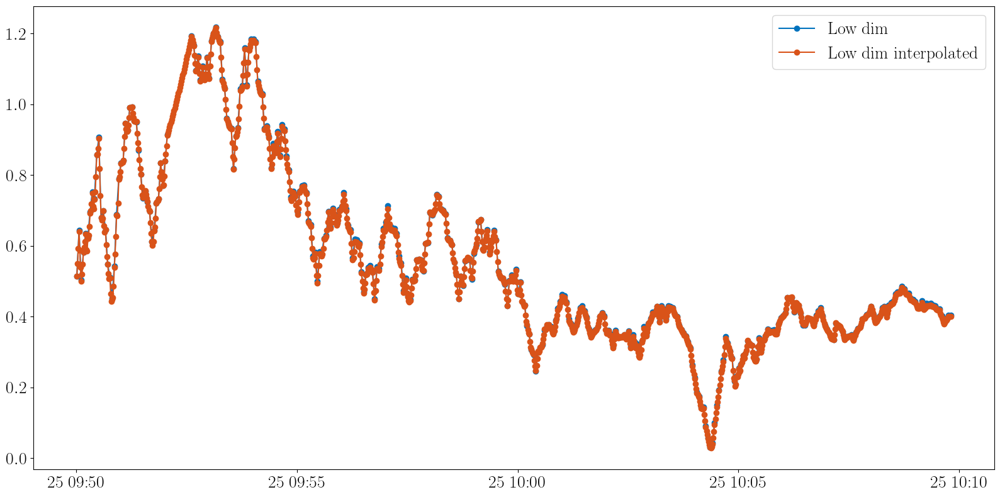

In [45]:
idx_ymin_low_dim = np.abs(ds_feature_section2.src_datetime - ymin_low_dim).argmin(
    dim="src_datetime"
)
line_L2_low_dim = dist_low_dim[:, idx_ymin_low_dim]
idx_ymin_low_dim_interp = np.abs(interp_times2 - ymin_low_dim_interp).argmin(

)
line_L2_low_dim_interp = dist_low_dim_interp[:, idx_ymin_low_dim_interp]

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_low_dim,
    "-o",
    color=color(0),
    label="Low dim",
)
plt.plot(
    interp_times1,
    line_L2_low_dim_interp,
    "-o",
    color=color(1),
    label="Low dim interpolated",
)

plt.legend()

Pas de distorsion visible en 1D. La stratégie envisagée reste a priori viable. 

Cependant, ici la couverture spatiale n'a pas vraiment augmenté (seulement la densité de point selon chaque trajectoire). 

#### Cas 2D

##### Projection dans le repère ENU 
Afin de simplifier les calculs on projette les coordonnées dans un repère local ENU centré sur la position moyenne des répliques considérée. 

In [47]:
N_geoid_undulation = 48.5
mean_lon, mean_lat = get_portion_tir_mean_pos(portion_tree=portion)
local_frame_origin = {"lon": mean_lon, "lat": mean_lat, "h": 0}  # MSL
get_enu_tir_pos(
    portion_tree=portion,
    local_frame_origin=local_frame_origin,
    N_geoid_undulation=N_geoid_undulation,
)
get_enu_rcv_pos(
    portion_tree=portion,
    local_frame_origin=local_frame_origin,
    N_geoid_undulation=N_geoid_undulation,
)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB 5.957 5.957 ... 5.957
│   │           atl_lat                 (atl_datetime) float64 9kB 43.05 43.05 ... 43.02
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB nan nan ... nan
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 3kB 55.41 54.67 ... 56.33
│   │           tir_src_n               (src_datetime) float64 3kB 1.643e+03 ... -1.548e+03
│   │           tir_src_u               (src_datetime) float64 3kB 43.29 43.29 ... 43.31
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 2kB -747.1 -739.4 ... 781.1
│   │           tir_src_n               (src_datetime) float64 2kB -647.7 -648.0 ... -644.9
│   │           tir_src_u               (src_datetime) float64 2kB 43.42 43.42 ... 43.42
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:   

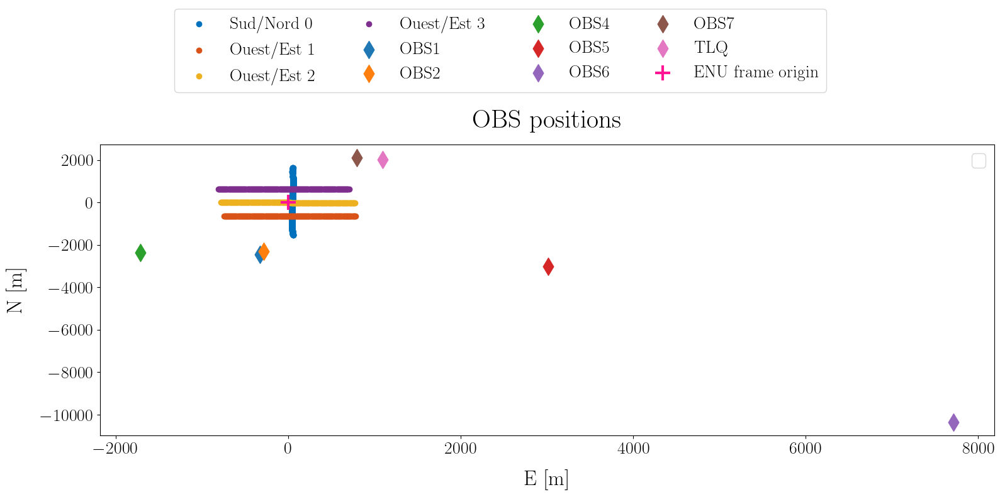

In [50]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

# Plot pos in ENU
plot_portion_tir_pos_enu(portion, ax=ax)
# Add local frame origin position
ax.scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
ax.legend(labels=[])

handles, labels = ax.get_legend_handles_labels()
ncols = min(len(labels), 4)
fig.legend(handles=handles, ncols=ncols, loc="outside upper center")


On considère un jeu de données composé de 2 trajectoires : 

* Ouest/Est 1
* Ouest/Est 2


In [78]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB 5.957 5.957 ... 5.957
│   │           atl_lat                 (atl_datetime) float64 9kB 43.05 43.05 ... 43.02
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB nan nan ... nan
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 3kB 55.41 54.67 ... 56.33
│   │           tir_src_n               (src_datetime) float64 3kB 1.643e+03 ... -1.548e+03
│   │           tir_src_u               (src_datetime) float64 3kB 43.29 43.29 ... 43.31
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 2kB -747.1 -739.4 ... 781.1
│   │           tir_src_n               (src_datetime) float64 2kB -647.7 -648.0 ... -644.9
│   │           tir_src_u               (src_datetime) float64 2kB 43.42 43.42 ... 43.42
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:   

In [316]:
section_1_name = "oe1"
section_2_name = "oe2"
section_event_name = "sn1"

# Create a new DataTree
lib_portion = xr.DataTree()

# Select the matching nodes from each top-level group
paths = list(portion.groups)
for group in list(portion.children):
    for section in [section_1_name, section_2_name]:
        path = f"/{group}/{section}"

        if path in paths:
            lib_portion[path] = portion[path].to_dataset()
lib_portion

# Add single event emission to dataset
isrc_dt_event = 200
augmented_lib_portion = lib_portion.copy()

paths = list(portion.groups)
for group in list(portion.children):
    path = f"/{group}/{section_event_name}"
    ds_event = portion[path].to_dataset()
    if group in ["position", "feature"]:
        ds_event = ds_event.isel(src_datetime=slice(isrc_dt_event, isrc_dt_event + 1))

    augmented_lib_portion[path] = ds_event

augmented_lib_portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 2kB -747.1 -739.4 ... 781.1
│   │           tir_src_n               (src_datetime) float64 2kB -647.7 -648.0 ... -644.9
│   │           tir_src_u               (src_datetime) float64 2kB 43.42 43.42 ... 43.42
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T03:0...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T03:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T03:0...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 2kB -782.5 -774.7 ... 777.4
│   │           tir_src_n               (src_datetime) float64 2kB 15.67 15.45 ... -13.44
│   │           tir_src_u               (src_datetime) float64 2kB 43.45 43.45 ... 43.45
│   │           rcv_e                   (rcv_id) float64 56B -326.2 -286.2 ... 1.098e+03
│   │           rcv_n                   (rcv_id) float64 56B -2.448e+03 ... 2.008e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.98 -67.93 ... -44.89 -44.91
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │       

##### IWD 

In [317]:
# Define interpolation grid
# npt = 100
# npt_e, npt_n  = npt, npt
de = 25
dn = 25
alpha_grid = 3

e_min = np.min(
    [
        feature_node.tir_src_e.min().values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)
e_max = np.max(
    [
        feature_node.tir_src_e.max().values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)
e_min = e_min - alpha_grid * de
e_max = e_max + alpha_grid * de

# e = np.linspace(e_min, e_max, npt_e)
e = np.arange(e_min, e_max, de)

n_min = np.min(
    [
        feature_node.tir_src_n.min().values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)
n_max = np.max(
    [
        feature_node.tir_src_n.max().values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)
n_min = n_min - alpha_grid * dn
n_max = n_max + alpha_grid * dn

# n = np.linspace(n_min, n_max, npt_n)
n = np.arange(n_min, n_max, dn)

ee, nn = np.meshgrid(e, n)

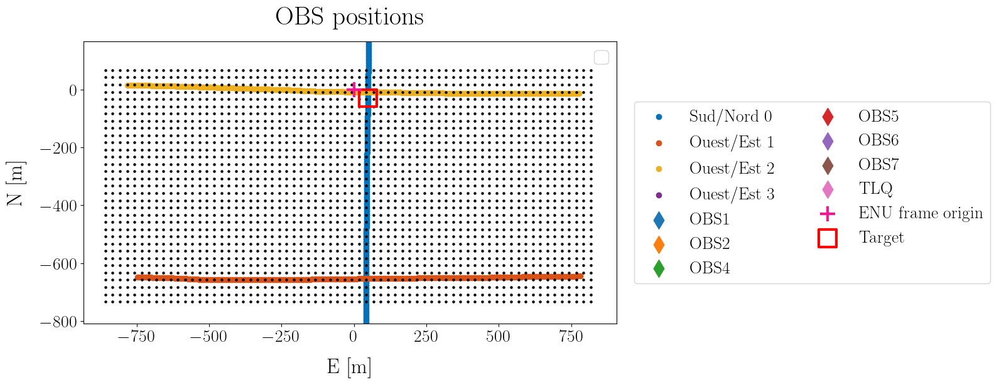

In [318]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

# Plot pos in ENU
plot_portion_tir_pos_enu(portion, ax=ax)
# Add local frame origin position
ax.scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
ax.scatter(ee.flatten(), nn.flatten(), marker="o", s=5, color="k")

ax.scatter(
    ds_event.tir_src_e,
    ds_event.tir_src_n,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

ax.legend(labels=[])


plt.xlim(e_min-3*de, e_max+3*de)
plt.ylim(n_min-3*dn, n_max+3*dn)

ax.set_aspect("equal")

handles, labels = ax.get_legend_handles_labels()
ncols = min(len(labels), 4)
fig.legend(handles=handles, ncols=2, loc="outside right center", )

In [319]:
def derive_features_array(portion, fmin=5, fmax=50, rcv_ref="obs1", rcv_i="obs2"):
    pi_ij_arr = []
    gamma_arr = []
    sij_scot_arr = []
    for _, feature_node in portion.feature.children.items():
        ds_feature_section = feature_node.to_dataset()

        # Derive feature for current section
        pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
            ds_feature_section=ds_feature_section,
            fmin=fmin,
            fmax=fmax,
            rcv_ref=ref_rcv_id,
            rcv_i=rcv_id_i,
        )
        pi_ij_arr.append(pi_ij_a)
        gamma_arr.append(gamma_a)
        sij_scot_arr.append(sij_scot_a)

    # Build data
    data_pi = np.concatenate(
        pi_ij_arr, axis=0
    )  # (n_sample, n_features) = (sum(nti), nfreq)
    data_gamma = np.concatenate(
        gamma_arr, axis=0
    )  # (n_sample, n_features) = (sum(nti), nfreq)
    data_sij_scot = np.concatenate(
        sij_scot_arr, axis=0
    )  # (n_sample, n_features) = (sum(nti), nfreq)

    return data_pi, data_gamma, data_sij_scot

In [320]:
rcv_id_i = "obs4"
ref_rcv_id = "obs1"

fmin = 5
fmax = 50

data_pi, data_gamma, data_sij_scot = derive_features_array(
    lib_portion,
    fmin=5,
    fmax=50,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)

# Add event
# Derive feature for event
pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
    ds_feature_section=ds_event,
    fmin=fmin,
    fmax=fmax,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)

# Append in last position
data_pi = np.vstack([data_pi, pi_ij_a])
data_gamma = np.vstack([data_gamma, gamma_a])
data_sij_scot = np.vstack([data_sij_scot, sij_scot_a])

# data_pi, data_gamma, data_sij_scot = derive_features_array(
#     augmented_lib_portion,
#     fmin=5,
#     fmax=50,
#     rcv_ref=ref_rcv_id,
#     rcv_i=rcv_id_i,
# )

# pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
#     ds_feature_section=ds_feature_section1,
#     fmin=fmin,
#     fmax=fmax,
#     rcv_ref=ref_rcv_id,
#     rcv_i=rcv_id_i,
# )
# pi_ij_b, gamma_b, sij_scot_b = derive_section_features(
#     ds_feature_section=ds_feature_section2,
#     fmin=fmin,
#     fmax=fmax,
#     rcv_ref=ref_rcv_id,
#     rcv_i=rcv_id_i,
# )

# features_section1 = dict(pi_ij=pi_ij_a, gamma_ij=gamma_a, sij_scot=sij_scot_a)
# features_section2 = dict(pi_ij=pi_ij_b, gamma_ij=gamma_b, sij_scot=sij_scot_b)

# dist_theta, dist_theta_gamma, dist_L2_gamma, dist_dcf = (
#     derive_feature_distance_between_sections(features_section1, features_section2)
# )

In [354]:
# Apply ISOMAP to derive coords
n_components = 100
n_neighbors = 5

# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    metric="precomputed",
)


data_a = data_gamma[:, np.newaxis, :]
data_b = data_gamma[np.newaxis, :, :]

# Compute theta with gamma
inner_prod = np.nansum(data_a * data_b, axis=-1)
norm_a = np.sqrt(np.nansum(data_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(data_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_data = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1] -> shape (nt1 + nt2, nt1 + nt2)

# # Compute dist with L2
# dist_data = np.sqrt(np.nansum(np.abs(data_a - data_b) ** 2, axis=-1))
# dist_data = dist_data / np.nanmax(dist_data)  # Normalize to [0, 1]

# Learn manifold and project data in target dimension
coords = isomap_obj.fit_transform(dist_data)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

# Get event coords
event_coords = coords[-1, :]
coords = coords[:-1, :]

In [355]:
e_lib = np.concat(
    [
        feature_node.tir_src_e.values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)
n_lib = np.concat(
    [
        feature_node.tir_src_n.values
        for _, feature_node in lib_portion.feature.children.items()
    ]
)

ee_flat = ee.flatten()
nn_flat = nn.flatten()

de_grid_lib = ee_flat[:, np.newaxis] - e_lib[np.newaxis, :]  # (n_ee, n_elib)
dn_grid_lib = nn_flat[:, np.newaxis] - n_lib[np.newaxis, :]  # (n_nn, n_nlib)
r_grid_lib = np.sqrt(de_grid_lib**2 + dn_grid_lib**2)

# # check this is okay
# i, j = -1, -1
# print(f"Distance from grid point of coords e={ee_flat[i]}, n={nn_flat[i]} : {r_grid_lib[i, :]}")
# # Non vectorized calc for comparison
# e_test = ee_flat[i]
# n_test = nn_flat[i]
# r_test = np.sqrt((e_test - e_lib)**2 + (n_test - n_lib)**2)
# print(np.allclose(r_test, r_grid_lib[i, :]))

In [356]:
coords.shape, r_grid_lib.shape

((394, 100), (2244, 394))

In [357]:
# Interpolate each coords in low dim
i = 0
power = 1

low_dim = 10
coords_low_dim = coords[:, :low_dim]
coords_low_dim_grid = np.empty((ee_flat.shape[0], coords_low_dim.shape[1]))
for i in range(low_dim):
    psi_i = coords_low_dim[:, i]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(psi_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    psi_i_interp = numerator / weights

    coords_low_dim_grid[:, i] = psi_i_interp

# Reshape
coords_low_dim_grid = np.reshape(
    coords_low_dim_grid, ee.shape + (coords_low_dim_grid.shape[1],)
)

In [359]:
coords_low_dim_grid.shape, e.shape, n.shape

((33, 68, 10), (68,), (33,))

Text(0.02, 0.5, 'N [m]')

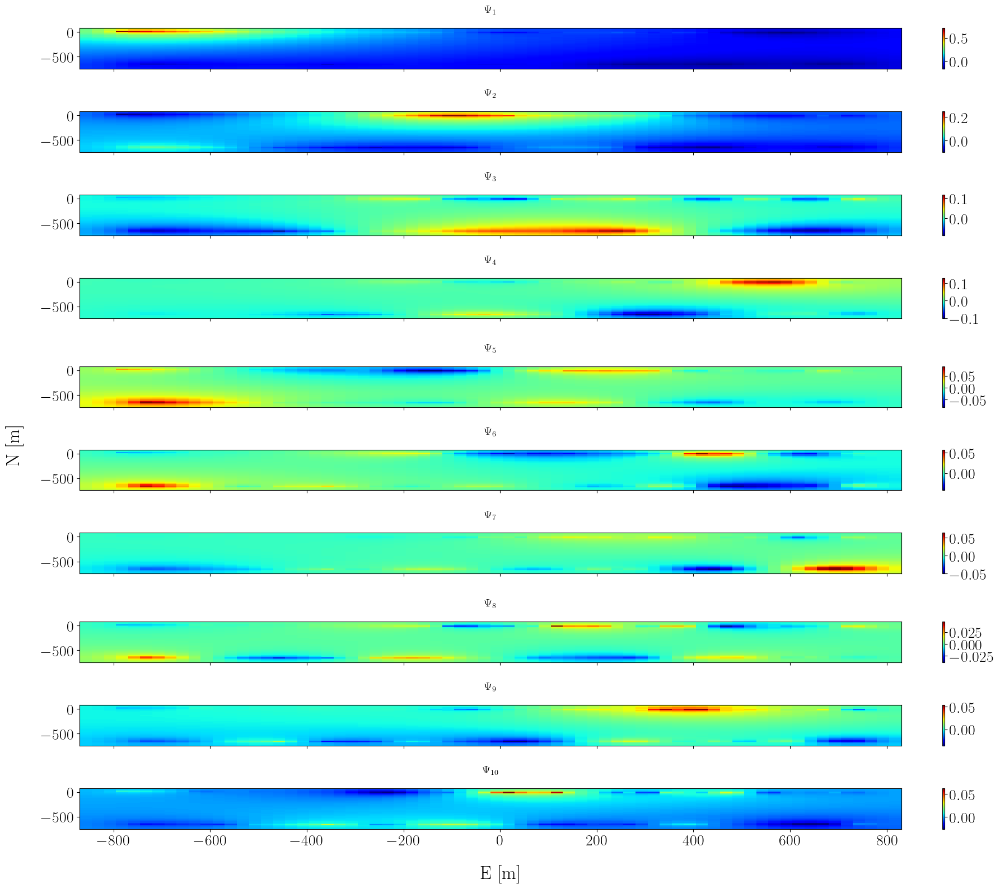

In [360]:
fig, axs = plt.subplots(
    nrows=low_dim, ncols=1, figsize=(18, 16), sharex=True, sharey=True
)
axs = axs.flatten()
for i in range(low_dim):

    psi_i_interp = coords_low_dim_grid[:, :, i]
    # Plot
    im = axs[i].pcolormesh(
        e,
        n,
        psi_i_interp,
        cmap="jet",
        # vmin=np.nanmin(dist_low_dim),
        # vmax=np.nanpercentile(dist_low_dim, 0.9),
        # vmin=vmin,
        # vmax=vmax,
    )
    plt.colorbar(im, ax=axs[i])

    axs[i].set_title(
        rf"$\Psi_{{{i+1}}}$", fontsize=14
    )

# for ax in axs.flatten():
#     ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"E [m]"
)
fig.supylabel(
    f"N [m]"
)

In [361]:
event_coords_low_dim = event_coords[:low_dim]
# coords_low_dim_grid.shape, event_coords_low_dim[np.newaxis, np.newaxis, :].shape
(coords_low_dim_grid - event_coords_low_dim[np.newaxis, np.newaxis, :]).shape

(33, 68, 10)

In [362]:
# Compute L2 distance in low dimension
# dist_low_dim = np.sqrt(
#     np.nansum((coords_low_dim_a[:, np.newaxis, :] - coords_low_dim_b[np.newaxis, :, :]) ** 2, axis=-1)
# )

# xmin_low_dim, ymin_low_dim = find_min_distance_position(
#     dt1=ds_feature_section1.src_datetime,
#     dt2=ds_feature_section2.src_datetime,
#     dist=dist_low_dim.T,
# )

# Test de loc

# Compute L2 distance in low dimension
event_coords_low_dim = event_coords[:low_dim]
dist_low_dim_grid = np.sqrt(
    np.nansum(
        (coords_low_dim_grid - event_coords_low_dim[np.newaxis, np.newaxis, :]) ** 2,
        axis=-1,
    )
)

In [363]:
dist_low_dim_grid.shape

(33, 68)

Text(0.02, 0.5, 'N [m]')

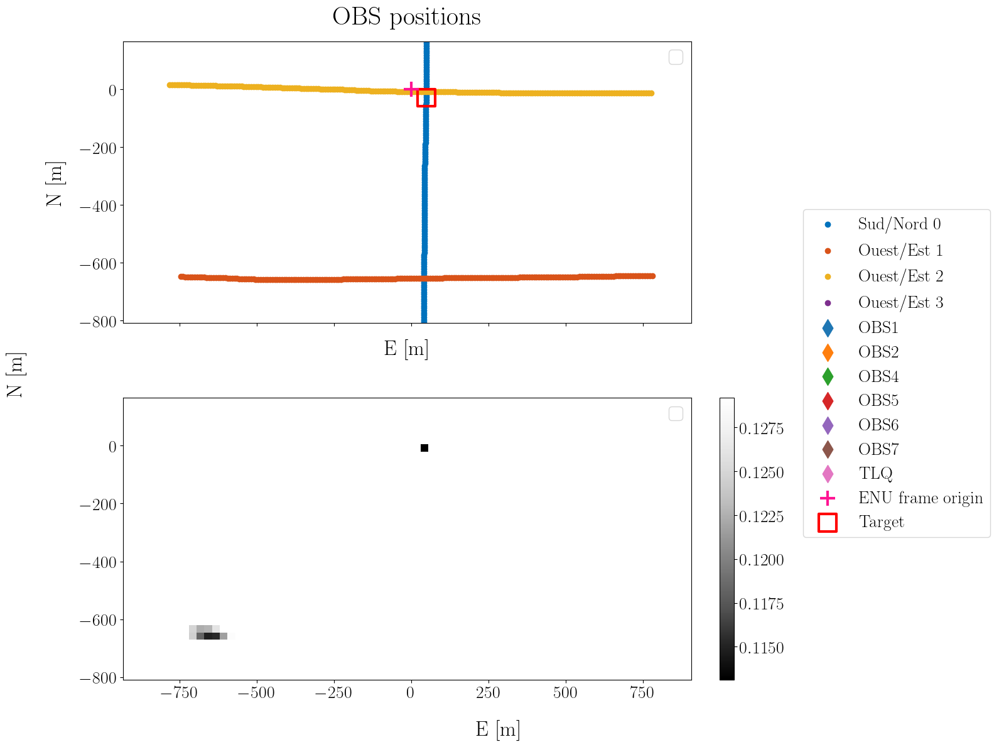

In [368]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
axs = axs.flatten()

# Plot pos in ENU
plot_portion_tir_pos_enu(portion, ax=axs[0])
# Add local frame origin position
axs[0].scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
axs[0].legend(labels=[])

# plt.scatter(ee.flatten(), nn.flatten(), marker="o", s=5, color="k")

# Add event position
path = f"/feature/{section_event_name}"
ds_event = augmented_lib_portion[path].to_dataset()

for ax in axs:
    ax.scatter(
        ds_event.tir_src_e,
        ds_event.tir_src_n,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="r",
        label="Target",
        linewidth=3,
    )
    ax.legend(labels=[])


plt.xlim(e_min - 3 * de, e_max + 3 * de)
plt.ylim(n_min - 3 * dn, n_max + 3 * dn)

# axs[0].set_aspect("equal")

handles, labels = axs[0].get_legend_handles_labels()
ncols = min(len(labels), 4)
fig.legend(
    handles=handles,
    ncols=1,
    loc="outside right center",
)

# Plot
im = axs[1].pcolormesh(
    e,
    n,
    dist_low_dim_grid,
    cmap="Grays_r",
    vmin=np.nanmin(dist_low_dim_grid),
    vmax=np.nanpercentile(dist_low_dim_grid, 0.5),
)
plt.colorbar(im, ax=axs[1])


# for ax in axs.flatten():
#     ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(f"E [m]")
fig.supylabel(f"N [m]")

In [365]:
from scipy.interpolate import LinearNDInterpolator

# X, Y = np.meshgrid(X, Y)  # 2D grid for interpolation
# interp = LinearNDInterpolator(list(zip(x, y)), z)
# Z = interp(X, Y)

Avant d'interpoler on 